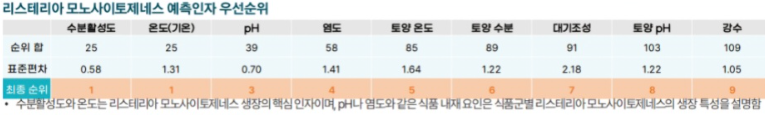

1. `data/X.parquet`, `data/y.parquet` 로드 (y 에 `lims_data_key` 있음 → 키로 X·y 맞춤)
2. 데이터 분할 (`EXP/1/readme.md` 기간, 기준일 `mnfctur_de`) — 국내·해외는 나누지 않음
   - train ~2024-06-30 / val 2024-07-01~2025-06-30 / test 2025-07-01~2026-06-30
3. 기상 조인 규칙
   - 기간: 기준일 D-1~D-100 (변수마다 100칼럼)
   - 국내 행: 시료 `lat`·`lon` 에서 유클리드 거리로 가까운 관측소 3곳 평균 (그날 값 있는 관측소 중, 동방로거테스트 포함) — ASOS 는 그날 운영 중이던 관측소 위치
   - 해외 행: `api_data_info.global_factory_weather` 에서 시료와 같은 좌표 값
   - 국내·해외 값을 같은 칼럼에 넣음. 기본 칼럼이 비면 대체 칼럼, 그래도 없으면 결측 그대로
   - ASOS·에어코리아 자료는 2015-01-01 부터 → 기준일이 가장 이른 1행(2015-04-07)은 D-100~D-97(2014-12-28~31)이 NAS 대체 없는 변수에서 빈칸 (NAS 는 2008년부터)
4. 넣는 변수 (리서치팀 빨간 글자 중 DB 에 있는 것) — 국내 기본(→대체) / 해외
   - 평균기온: ASOS `avg_ta` (→NAS `temp`) / `temperature_mean`
   - 최고기온: ASOS `max_ta` (→NAS `hghst_artmp`) / `temperature_max`
   - 최저기온: ASOS `min_ta` (→NAS `lowst_artmp`) / `temperature_min`
   - 강수량: NAS `rn` / `precipitation_sum`
   - 평균풍속: ASOS `avg_ws` (→NAS `wind`) / 없음
   - 최대풍속: ASOS `max_ws` (→NAS `max_wind`) / 없음
   - 일조시간: ASOS `sum_sshr` / 없음
   - 일사량: ASOS `sum_gsr` (→NAS `srqty`) / `radiation_sum`
   - 지중온도 5·10·20·30cm: ASOS `avg_cm5_te`·`avg_cm10_te`·`avg_cm20_tes`·`avg_cm30_te` / 없음
   - 지중온도(NAS, 깊이 설명 없음): NAS `soil_temp` / 없음
   - 토양수분: NAS `soil_wt` / 없음
   - 이산화질소·일산화탄소·아황산가스: 에어코리아 `no2_value`·`co_value`·`so2_value` (가까운 측정소 3곳) / 없음
   - 식품: `ba_data.t_aw_cl` 수분활성도 `aw`·식품pH `ph`·염도 `na` — `prdlst_code` 정확 일치 → 없으면 `train_prdlst_code`, 그래도 없으면 결측 그대로. 텍스트 값은 범위 → 가운데 값, 부등호 → 경계값, 그 밖(`-` 등) → 결측. **값이 어떤 표기에서 왔는지(단일값·중앙·이상·이하·초과·미만)를 `aw_label`·`ph_label`·`na_label` 칼럼으로 함께 남긴다 (2026-10-01 추가)**
5. 뺀 것과 사유
   - 단위가 달라 해외 값만 뺌: 풍속(해외 km/h, 국내 m/s), 일조(해외 초, 국내 시간), 토양수분(해외 m³/m³, 국내 %)
   - 단위·뜻이 달라 대체 안 함: 일조 NAS `sun_time`(분), 강수 ASOS `sum_rn`(빈칸 = 비 안 온 날)
   - 풍향: 각도라 3곳 평균이 안 됨(350°와 10°의 평균이 180°)
   - 토양 pH·유기물·유효인산: 필지 좌표가 DB 에 없음
   - 대기조성(이산화탄소), 방재기상(AWS), 기상청 농업기상(AAOS), 농업기상 상세관측·팜맵(높이·깊이별 값), 미래 기후도, 토양수분량(수자원공사·유역별·흙토람), 염분·해상풍, 지하수 오염도: DB 에 없음
   - 수질오염원 설치시설: 시설 위치 목록이라 주변 시설 수 세기 같은 가공이 필요
   - `weather_data.*`·`staging_data.kma_wind_daily`: 보간 등 가공된 테이블이라 원자료 ASOS·NAS 사용
6. 학습 입력에서 조인키 제거 (`lims_data_key`, `mnfctur_de`)
7. 학습: `2_바로학습.ipynb` 와 같은 방식 (XGBoost·LightGBM·CatBoost 기본값, 불균형 처리 없음) — CatBoost 는 GPU
   - val 은 임계값 고르기에만 (early stopping 안 함)
   - 임계값 0.5 / val F1최대 / val F2최대, 지표는 readme 목록
8. 비교: `2_바로학습.ipynb` 결과 (같은 행·같은 분할)
9. 기록: MLflow
10. (2026-10-01 변경) 입력 `X.parquet` 가 바뀌었다: `inspct_instt_code`(검사기관 코드) 제거, 로마자로 적힌 한국 주소 78행을 `src_route` domestic 으로 옮김(`1_데이터정제.ipynb`). 그래서 이 78행에는 국내 관측소 값이 붙는다.

# 실험 1 3단계 — 기상·대기·식품 인자 조인 후 학습

`2_바로학습.ipynb`(정제만 한 데이터)와 **같은 행·같은 분할·같은 모델 설정**에 식정원 DB(TOXIN_MODEL_PRED)의 기상·대기·식품 인자를 붙여, 성능이 오르는지 본다. 계획은 바로 위 셀이다.

| 항목 | 내용 |
|---|---|
| 입력 | `data/X.parquet`, `data/y.parquet` + 식정원 DB 원자료(`data/collected/raw/`) |
| 조인 결과 | `data/collected/exp1_wx/` — 기상·대기 변수마다 parquet 1개(17개) + 식품 1개 |
| 붙인 칼럼 | 기상·대기 17개 변수 × D-1~D-100 = 1,700칼럼 + 식품 3칼럼(수분활성도·식품pH·염도) + 식품 값 표기 3칼럼(`aw_label`·`ph_label`·`na_label`) |
| 분할 | 2_바로학습과 같음 — train ~2024-06-30 · val 2024-07-01~2025-06-30 · test 2025-07-01~2026-06-30 |
| 모델 | XGBoost·LightGBM·CatBoost 기본 하이퍼파라미터, seed 42, 불균형 처리·조기 종료 없음 |
| 장치 | XGBoost GPU · LightGBM CPU · CatBoost **GPU**(사용자 결정 2026-09-29). 2_바로학습의 CatBoost 는 CPU 라, CatBoost 비교에는 장치 차이도 섞인다 |
| 결과 기록 | MLflow 실험 `리스테리아_EXP1` 의 run `3_기상조인_후_학습` (파일로 따로 저장하지 않음) |

**절 구성**: 1 설정 → 2 데이터 불러오기 → 3 식정원 DB 원자료 받기 → 4 조인(기상·대기) → 5 조인(식품) → 6 조인 점검 → 7 분할 → 8 모델 입력 → 9 학습 → 10 예측·임계값·평가 → 11 그림 → 12 칼럼 중요도 → 13 MLflow 기록 → 14 2_바로학습과 비교 → 15 결론

## 1. 설정

경로·seed·장치·분할 날짜·조인 설정·MLflow 기록 위치를 이 셀 하나에 모은다.

- `FORCE_DB = False`: `data/collected/raw/` 에 원자료 파일이 있으면 DB 에 다시 가지 않는다. `True` 면 다시 받는다.
- `FORCE_JOIN = False`: `data/collected/exp1_wx/` 에 조인 결과가 있으면 다시 만들지 않는다. 조인 규칙을 바꾸면 `True` 로 돌린다.
- 장치: CatBoost 는 GPU(사용자 결정). GPU 는 같은 seed 로도 실행마다 결과가 조금씩 다르다(2_바로학습 5-3절).

In [1]:
import gc
import json
import logging
import os
import re
import sys
import tempfile
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import psycopg
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import sklearn
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')   # mlflow 가 찍는 LLM 추적 안내 문구 끄기
import mlflow
from dotenv import dotenv_values
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
)

SEED = 42
DEVICE = {'XGBoost': 'cuda', 'LightGBM': 'cpu', 'CatBoost': 'GPU'}   # CatBoost GPU — 사용자 결정 2026-09-29

# 분할 날짜 — mnfctur_de 기준, 양 끝 날짜 포함 (2_바로학습과 같음)
TRAIN_END = '2024-06-30'
VAL_START, VAL_END = '2024-07-01', '2025-06-30'
TEST_START, TEST_END = '2025-07-01', '2026-06-30'
KEY_COL = 'lims_data_key'   # 행 키 — 피처에서 제외
DATE_COL = 'mnfctur_de'     # 분할·기상 기준일 — 피처에서 제외

# 경로
PROJECT_DIR = Path(r'C:\Users\NT751\Desktop\천영진\리스테리아ML')
ENV_PATH = PROJECT_DIR / '.env'
X_path = PROJECT_DIR / 'data' / 'X.parquet'
y_path = PROJECT_DIR / 'data' / 'y.parquet'
RAW_DIR = PROJECT_DIR / 'data' / 'collected' / 'raw'        # DB 원자료 (SELECT * 그대로)
JOIN_DIR = PROJECT_DIR / 'data' / 'collected' / 'exp1_wx'   # 조인 결과
FORCE_DB = False
FORCE_JOIN = False   # 2026-10-01 에 X.parquet 변경(78행 국내로)에 맞춰 True 로 다시 만들었다. X 나 조인 규칙이 바뀌면 True

# 조인 설정
LAG_DAYS = 100          # 기준일 전날(D-1) ~ 100일 전(D-100). 기준일 당일(D0)은 넣지 않는다
K_NEAREST = 3           # 국내: 가까운 관측소 3곳 평균
TOP_CANDIDATES = 60     # 계산을 빠르게 하려고 좌표마다 거리순 60곳을 먼저 본다. 60곳 안에 그날 값 있는 곳이 3곳보다 적으면 전체 관측소에서 다시 찾는다

# MLflow — 2_바로학습과 같은 곳·같은 실험
MLFLOW_URI = dotenv_values(ENV_PATH).get('AFLA_MLFLOW_URI')   # .env 에서 이 키 하나만 읽는다
assert MLFLOW_URI, '.env 에 AFLA_MLFLOW_URI 가 없음'
if MLFLOW_URI.startswith('sqlite:///') and not Path(MLFLOW_URI.removeprefix('sqlite:///')).is_absolute():
    MLFLOW_URI = 'sqlite:///' + (PROJECT_DIR / MLFLOW_URI.removeprefix('sqlite:///')).as_posix()
MLFLOW_ARTIFACTS = PROJECT_DIR / 'mlruns'
MLFLOW_EXPERIMENT = '리스테리아_EXP1'
RUN_NAME = '3_기상조인_후_학습'
logging.getLogger('alembic').setLevel(logging.WARNING)
mlflow.set_tracking_uri(MLFLOW_URI)
if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
    mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=MLFLOW_ARTIFACTS.as_uri())
mlflow.set_experiment(MLFLOW_EXPERIMENT)

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
warnings.filterwarnings('ignore', message='.*Falling back to prediction using DMatrix')

print('장치:', DEVICE)
print('MLflow:', MLFLOW_URI, '| 실험', MLFLOW_EXPERIMENT, '| run', RUN_NAME)
print('xgboost', xgb.__version__, '| lightgbm', lgb.__version__, '| catboost', cb.__version__,
      '| scikit-learn', sklearn.__version__, '| mlflow', mlflow.__version__)

장치: {'XGBoost': 'cuda', 'LightGBM': 'cpu', 'CatBoost': 'GPU'}
MLflow: sqlite:///C:/Users/NT751/Desktop/천영진/리스테리아ML/mlflow.db | 실험 리스테리아_EXP1 | run 3_기상조인_후_학습
xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10 | scikit-learn 1.9.1 | mlflow 3.16.1


## 2. 데이터 불러오기

2_바로학습과 같다. `y` 는 행 키 `lims_data_key` 로 X 의 행 순서에 맞춘다.

기상 기간의 양 끝도 여기서 정한다: 가장 이른 기준일의 D-100 부터 가장 늦은 기준일의 D-1 까지.

In [2]:
X = pd.read_parquet(X_path)
y_df = pd.read_parquet(y_path)   # lims_data_key + judge_result
assert y_df[KEY_COL].is_unique and X[KEY_COL].is_unique
y = (y_df.set_index(KEY_COL)['judge_result'].reindex(X[KEY_COL]).set_axis(X.index))
assert y.notna().all(), 'X 의 lims_data_key 중 y 에 없는 행이 있음'

DATE_MIN = X[DATE_COL].min() - pd.Timedelta(days=LAG_DAYS)   # 가장 이른 기준일의 D-100
DATE_MAX = X[DATE_COL].max() - pd.Timedelta(days=1)          # 가장 늦은 기준일의 D-1
DATES = pd.date_range(DATE_MIN, DATE_MAX, freq='D')
IS_DOM = (X['src_route'].astype(str) == 'domestic').to_numpy()

# 좌표 — X.parquet 에는 lat·lon 이 없다(2026-10-01, 1_데이터정제에서 모델 피처에서 제거).
# 기상 조인에만 쓰려고 원자료 listeria_body.parquet 에서 lims_data_key 로 가져온다(X 와 같은 행 순서·index). 모델 피처에는 넣지 않는다
BODY_PATH = PROJECT_DIR / 'data' / 'listeria_body.parquet'
XY = pd.read_parquet(BODY_PATH, columns=[KEY_COL, 'lat', 'lon']).set_index(KEY_COL)
assert XY.index.is_unique
XY = XY.reindex(X[KEY_COL]).set_axis(X.index)
assert XY.notna().all().all(), 'X 의 lims_data_key 중 listeria_body.parquet 에 좌표가 없는 행이 있음'
assert (XY.dtypes == 'float32').all()

print('X', X.shape, '| y', y.shape, '| 검출', int(y.sum()))
print(f'국내 {IS_DOM.sum():,}행 · 해외 {(~IS_DOM).sum():,}행')
print('기상 기간:', DATE_MIN.date(), '~', DATE_MAX.date(), f'({len(DATES):,}일)')

X (676537, 11) | y (676537,) | 검출 1969
국내 628,973행 · 해외 47,564행
기상 기간: 2014-12-28 ~ 2026-06-29 (4,202일)


## 3. 식정원 DB 원자료 받기

- 접속: `리스테리아ML/.env` 의 `DB_HOST`·`DB_PORT`·`DB_NAME`·`DB_USER`·`DB_PASSWORD` (값은 출력하지 않는다). 세션을 **읽기 전용**(`default_transaction_read_only=on`)으로 열고 SELECT 만 한다. 서버에 TEMP 테이블 등 아무것도 만들지 않는다.
- 받은 그대로(`SELECT *`, 값·단위 변환 없음) `data/collected/raw/raw_<테이블>.parquet` 로 저장하고, 조인은 이 파일로 한다.

| 파일 | DB 테이블 | 무엇 | 받는 범위 |
|---|---|---|---|
| `raw_kma_asos_daily_info` | `api_data_info.kma_asos_daily_info` | 기상청 종관기상관측(ASOS) 일자료 | 전체 |
| `raw_kma_ground_obs_station_info` | `api_data_info.kma_ground_obs_station_info` | ASOS 지점 정보(위치 이력 포함) | 전체 |
| `raw_nas_agri_weather_daily_info` | `api_data_info.nas_agri_weather_daily_info` | 농촌진흥청 농업기상 기본관측(NAS) 일자료 | 전체 |
| `raw_nas_agri_weather_obs_station` | `api_data_info.nas_agri_weather_obs_station` | NAS 관측지점 정보 | 전체 |
| `raw_keco_airkorea_fine_dust_info` | `api_data_info.keco_airkorea_fine_dust_info` | 에어코리아 대기오염 일평균 | 전체 |
| `raw_keco_airkorea_obs_station` | `api_data_info.keco_airkorea_obs_station` | 에어코리아 측정소 정보 | 전체 |
| `raw_t_aw_cl` | `ba_data.t_aw_cl` | 품목별 수분활성도·식품pH·염도 | 전체 |
| `raw_global_factory_weather_listeria` | `api_data_info.global_factory_weather` | 해외 제조업소 좌표 일별 기상(ERA5) | **해외 시료 좌표 × 기상 기간만** (테이블이 약 2.3억 행이라) |

In [3]:
def connect():
    """읽기 전용 세션으로 접속 — .env 의 DB_* 키만 읽고 값은 출력하지 않는다"""
    e = dotenv_values(ENV_PATH)
    conn = psycopg.connect(host=e['DB_HOST'], port=int(e.get('DB_PORT') or 5432), dbname=e['DB_NAME'],
                           user=e['DB_USER'], password=e.get('DB_PASSWORD') or None,
                           options='-c default_transaction_read_only=on',
                           application_name='listeria_exp1_wx_join', connect_timeout=15)
    with conn.cursor() as cur:
        cur.execute('show default_transaction_read_only')
        assert cur.fetchone()[0] == 'on', '읽기 전용 세션이 아님'
    return conn


def fetch_to_parquet(conn, sql, params, out_path, chunk=500_000):
    """서버측 커서로 나눠 받아 parquet 로 저장. DB 의 numeric(Decimal)은 float64 로만 바꾸고 값은 그대로 둔다"""
    import decimal
    out_path = Path(out_path)
    tmp = out_path.with_suffix('.parquet.part')
    writer, schema, n = None, None, 0
    with conn.transaction():
        with conn.cursor(name='exp1_fetch') as cur:
            cur.itersize = chunk
            cur.execute(sql, params)
            cols = [d.name for d in cur.description]
            while rows := cur.fetchmany(chunk):
                df = pd.DataFrame(rows, columns=cols)
                for c in df.columns:
                    nn = df[c].dropna()
                    if df[c].dtype == object and len(nn) and isinstance(nn.iloc[0], decimal.Decimal):
                        df[c] = pd.to_numeric(df[c]).astype('float64')
                table = pa.Table.from_pandas(df, preserve_index=False)
                if writer is None:
                    schema = table.schema
                    writer = pq.ParquetWriter(tmp, schema)
                writer.write_table(table.cast(schema))
                n += len(df)
    writer.close()
    os.replace(tmp, out_path)
    return n


RAW_TABLES = {   # 파일 이름 → SQL
    'raw_kma_asos_daily_info':          'select * from api_data_info.kma_asos_daily_info',
    'raw_kma_ground_obs_station_info':  'select * from api_data_info.kma_ground_obs_station_info',
    'raw_nas_agri_weather_daily_info':  'select * from api_data_info.nas_agri_weather_daily_info',
    'raw_nas_agri_weather_obs_station': 'select * from api_data_info.nas_agri_weather_obs_station',
    'raw_keco_airkorea_fine_dust_info': 'select * from api_data_info.keco_airkorea_fine_dust_info',
    'raw_keco_airkorea_obs_station':    'select * from api_data_info.keco_airkorea_obs_station',
    'raw_t_aw_cl':                      'select * from ba_data.t_aw_cl',
}
RAW_DIR.mkdir(parents=True, exist_ok=True)
todo = [f for f in RAW_TABLES if FORCE_DB or not (RAW_DIR / f'{f}.parquet').exists()]
if todo:
    with connect() as conn:
        for f in todo:
            t0 = time.time()
            n = fetch_to_parquet(conn, RAW_TABLES[f], None, RAW_DIR / f'{f}.parquet')
            print(f'받음 {f}: {n:,}행 ({time.time() - t0:.0f}초)')
for f in RAW_TABLES:
    p = RAW_DIR / f'{f}.parquet'
    print(f'{f:36s} {pq.ParquetFile(p).metadata.num_rows:>10,}행  받은 시각 {datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}')

raw_kma_asos_daily_info                 406,909행  받은 시각 2026-09-29 11:39
raw_kma_ground_obs_station_info             243행  받은 시각 2026-09-29 11:39
raw_nas_agri_weather_daily_info         984,648행  받은 시각 2026-09-29 11:39
raw_nas_agri_weather_obs_station            219행  받은 시각 2026-09-29 11:39
raw_keco_airkorea_fine_dust_info      2,150,630행  받은 시각 2026-09-29 11:39
raw_keco_airkorea_obs_station               753행  받은 시각 2026-09-29 11:39
raw_t_aw_cl                               1,316행  받은 시각 2026-09-29 11:39


### 3-1. 해외 제조업소 기상 `api_data_info.global_factory_weather` — 해외 시료 좌표만 받기

DB 코멘트상 이 테이블의 좌표 `lat_g`·`lon_g` 는 "hazard_preprocessed_data 원본 lat 과 동일 값(조인 키)"이다. 그런데 시료 파일(`X`)의 `lat`·`lon` 은 소수 정밀도가 낮은 float32 로 저장돼 있어 그대로 비교하면 하나도 같지 않다. 그래서 두 단계로 받는다.

1. **좌표 찾기**: 시료 좌표(float32)마다 "float32 로 바꾸면 그 값이 되는 DB 좌표(double) 범위"를 계산해, 그 범위 안의 DB 좌표를 찾는다. 좌표마다 인덱스(`lat_g, lon_g`)를 타도록 `LATERAL` 로 한 곳씩 찾는다.
2. **자료 받기**: 찾은 DB 좌표의 기상 기간 일자료를 `SELECT *` 로 받는다.

같은 시료 좌표로 반올림되는 DB 좌표가 2곳 이상이면 둘 다 받고, 4절에서 두 값의 평균을 쓴다(몇 곳인지 아래에 출력).

In [4]:
def f32_bounds(v):
    """float32 값 v 로 반올림되는 double 범위 [lo, hi]"""
    v = np.asarray(v, dtype=np.float32)
    up = np.nextafter(v, np.float32(np.inf)).astype(np.float64)
    dn = np.nextafter(v, np.float32(-np.inf)).astype(np.float64)
    v64 = v.astype(np.float64)
    return (v64 + dn) / 2, (v64 + up) / 2

GFW_PATH = RAW_DIR / 'raw_global_factory_weather_listeria.parquet'
OV_XY = XY.loc[~IS_DOM, ['lat', 'lon']].drop_duplicates().reset_index(drop=True)   # 해외 시료 좌표(float32)

SQL_FIND = """
select distinct g.lat_g, g.lon_g
from unnest(%s::float8[], %s::float8[], %s::float8[], %s::float8[]) as b(la_lo, la_hi, lo_lo, lo_hi)
cross join lateral (
    select distinct lat_g, lon_g from api_data_info.global_factory_weather
    where lat_g between b.la_lo and b.la_hi and lon_g between b.lo_lo and b.lo_hi
) g
"""
SQL_DATA = """
select g.*
from unnest(%s::float8[], %s::float8[]) as c(lat, lon)
cross join lateral (
    select * from api_data_info.global_factory_weather
    where lat_g = c.lat and lon_g = c.lon and obsr_de between %s and %s
) g
"""
if FORCE_DB or not GFW_PATH.exists():
    la_lo, la_hi = f32_bounds(OV_XY['lat'])
    lo_lo, lo_hi = f32_bounds(OV_XY['lon'])
    with connect() as conn:
        t0 = time.time()
        with conn.cursor() as cur:
            cur.execute(SQL_FIND, (la_lo.tolist(), la_hi.tolist(), lo_lo.tolist(), lo_hi.tolist()))
            grid = pd.DataFrame(cur.fetchall(), columns=['lat_g', 'lon_g'])
        print(f'1단계 좌표 찾기: 시료 좌표 {len(OV_XY):,}곳 → DB 좌표 {len(grid):,}곳 ({time.time() - t0:.0f}초)')
        t0 = time.time()
        n = fetch_to_parquet(conn, SQL_DATA, (grid['lat_g'].tolist(), grid['lon_g'].tolist(),
                                              DATE_MIN.date(), DATE_MAX.date()), GFW_PATH)
        print(f'2단계 자료 받기: {n:,}행 ({time.time() - t0:.0f}초)')
print(f'{GFW_PATH.name}: {pq.ParquetFile(GFW_PATH).metadata.num_rows:,}행')

raw_global_factory_weather_listeria.parquet: 12,900,454행


## 4. 조인 — 기상·대기 (17개 변수 × D-1~D-100)

### 조인 규칙

| 규칙 | 내용 |
|---|---|
| 날짜 | 기준일 = X 의 `mnfctur_de`. 기준일 전날(D-1)부터 100일 전(D-100)까지 하루씩. 칼럼 이름은 `<변수>_d001`(D-1) … `<변수>_d100`(D-100). 기준일 당일은 넣지 않는다 |
| 국내 행 | 시료 파일의 `lat`·`lon` 에서 **위경도 그대로 유클리드 거리**로 가까운 관측소 3곳의 **평균**. 관측소는 **그날 그 변수 값이 있는 곳 중에서** 고른다(3곳이 안 되면 있는 곳만 평균). 시험용 관측소 '동방로거테스트'(NAS `561034A001`)도 포함 |
| 관측소 좌표 | ASOS 는 지점 정보에 위치 이력(운영 시작일)이 있어 **그날 운영 중이던 위치**를 쓴다(연구 기간 안에 100m 넘게 옮긴 지점 12곳 — 천안 약 0.17도 등). NAS·에어코리아는 좌표가 하나뿐이라 그 좌표 |
| 대체 칼럼 | 국내 기본 칼럼이 그날 비면(그날 값 있는 관측소가 한 곳도 없으면) 대체 칼럼을 같은 방식으로 붙인다. 그래도 없으면 결측 그대로 |
| 해외 행 | `api_data_info.global_factory_weather` 에서 시료와 같은 좌표(3-1절)의 그날 값. 날짜 `obsr_de` 는 UTC 기준 날짜(DB 코멘트) |
| 국내·해외 | 같은 칼럼에 넣는다. 해외 자료가 없거나 단위가 달라 뺀 변수는 해외 행이 결측 |
| 값 | 원자료 그대로. 결측 채움·단위 변환·이상값 처리 없음 (ASOS `sum_sshr` 는 DB 에 텍스트로 들어 있어 숫자로만 바꿈 — 숫자 아닌 값 0건) |

### 4-1. 변수 정의

단위는 DB 코멘트·테이블정의서 기준. ASOS 풍속·일사량·일조는 정의서에 단위가 없어 값 범위로 판단했다(풍속 중앙값 ASOS 1.5 · NAS 0.8 m/s, 일사량 ASOS 13.8 · NAS 13.5 MJ/m², 일조 최댓값 14.1 → 시간).

In [5]:
# (칼럼 이름, 한글 이름, 단위, 국내 기본 (관측망, DB 칼럼), 국내 대체 또는 None, 해외 DB 칼럼 또는 None)
VARIABLES = [
    ('avg_temp',   '평균기온',        '°C',    ('ASOS', 'avg_ta'),       ('NAS', 'temp'),        'temperature_mean'),
    ('max_temp',   '최고기온',        '°C',    ('ASOS', 'max_ta'),       ('NAS', 'hghst_artmp'), 'temperature_max'),
    ('min_temp',   '최저기온',        '°C',    ('ASOS', 'min_ta'),       ('NAS', 'lowst_artmp'), 'temperature_min'),
    ('rain',       '강수량',          'mm',    ('NAS', 'rn'),            None,                   'precipitation_sum'),
    ('avg_wind',   '평균풍속',        'm/s',   ('ASOS', 'avg_ws'),       ('NAS', 'wind'),        None),
    ('max_wind',   '최대풍속',        'm/s',   ('ASOS', 'max_ws'),       ('NAS', 'max_wind'),    None),
    ('sunshine',   '일조시간',        '시간',  ('ASOS', 'sum_sshr'),     None,                   None),
    ('solar_rad',  '일사량',          'MJ/m²', ('ASOS', 'sum_gsr'),      ('NAS', 'srqty'),       'radiation_sum'),
    ('soil_t5',    '지중온도 5cm',    '°C',    ('ASOS', 'avg_cm5_te'),   None,                   None),
    ('soil_t10',   '지중온도 10cm',   '°C',    ('ASOS', 'avg_cm10_te'),  None,                   None),
    ('soil_t20',   '지중온도 20cm',   '°C',    ('ASOS', 'avg_cm20_tes'), None,                   None),
    ('soil_t30',   '지중온도 30cm',   '°C',    ('ASOS', 'avg_cm30_te'),  None,                   None),
    ('soil_t_nas', '지중온도(NAS, 깊이 정의서 설명 없음)', '°C', ('NAS', 'soil_temp'), None,    None),
    ('soil_moist', '토양수분',        '%',     ('NAS', 'soil_wt'),       None,                   None),
    ('no2',        '이산화질소',      'ppm',   ('AIR', 'no2_value'),     None,                   None),
    ('co',         '일산화탄소',      'ppm',   ('AIR', 'co_value'),      None,                   None),
    ('so2',        '아황산가스',      'ppm',   ('AIR', 'so2_value'),     None,                   None),
]
WX_VARS = [v[0] for v in VARIABLES]
WX_COLS = [f'{v}_d{k:03d}' for v in WX_VARS for k in range(1, LAG_DAYS + 1)]
NET_NAME = {'ASOS': 'ASOS(kma_asos_daily_info)', 'NAS': 'NAS(nas_agri_weather_daily_info)',
            'AIR': '에어코리아(keco_airkorea_fine_dust_info)'}
display(pd.DataFrame([{
    '칼럼': f'{v}_d001~d100', '변수': ko, '단위': unit,
    '국내 기본': f'{p[0]} `{p[1]}`', '국내 대체': f'{f[0]} `{f[1]}`' if f else '없음',
    '해외': f'`{o}`' if o else '없음'} for v, ko, unit, p, f, o in VARIABLES]))
print(f'기상·대기 칼럼 {len(WX_COLS):,}개')

,칼럼,변수,단위,국내 기본,국내 대체,해외
0,avg_temp_d001~d100,평균기온,°C,ASOS `avg_ta`,NAS `temp`,`temperature_mean`
1,max_temp_d001~d100,최고기온,°C,ASOS `max_ta`,NAS `hghst_artmp`,`temperature_max`
2,min_temp_d001~d100,최저기온,°C,ASOS `min_ta`,NAS `lowst_artmp`,`temperature_min`
3,rain_d001~d100,강수량,mm,NAS `rn`,없음,`precipitation_sum`
4,avg_wind_d001~d100,평균풍속,m/s,ASOS `avg_ws`,NAS `wind`,없음
5,max_wind_d001~d100,최대풍속,m/s,ASOS `max_ws`,NAS `max_wind`,없음
6,sunshine_d001~d100,일조시간,시간,ASOS `sum_sshr`,없음,없음
7,solar_rad_d001~d100,일사량,MJ/m²,ASOS `sum_gsr`,NAS `srqty`,`radiation_sum`
8,soil_t5_d001~d100,지중온도 5cm,°C,ASOS `avg_cm5_te`,없음,없음
9,soil_t10_d001~d100,지중온도 10cm,°C,ASOS `avg_cm10_te`,없음,없음


기상·대기 칼럼 1,700개


### 4-2. 관측망별 일자료·관측소 좌표

관측망마다 (날짜 × 관측소) 표를 만든다. 칸 값은 그날 그 관측소의 원자료 값이고, 자료 행이 없거나 값이 비면 NaN 이다.

- **ASOS**: 일자료 관측소 99곳. 좌표는 `kma_ground_obs_station_info` 의 `lat`·`lon`. 한 지점에 위치 행이 여러 개(운영 시작일 `oper_start_dt` 별)라, 날짜마다 "운영 시작일이 그날 이전인 행 중 가장 최근 행"의 좌표를 쓴다(그날 이전 행이 없으면 가장 이른 행).
- **NAS**: 일자료 관측소 219곳. 좌표는 `nas_agri_weather_obs_station` 의 `instl_la`(위도)·`instl_lo`(경도), 관측소당 1행.
- **에어코리아**: 일자료는 측정소 이름 `station_nm` 으로만 구분된다. 좌표는 `keco_airkorea_obs_station` 의 `dm_x`·`dm_y`(DB 코멘트 "WGS84 기반 X/Y 좌표". 값을 보면 `dm_x` 가 위도 범위, `dm_y` 가 경도 범위라 그렇게 쓴다 — 아래 출력으로 확인). 같은 이름이 두 행인 측정소 80곳은 주소 표기만 다르고 좌표가 같아 1행만 쓴다. 측정소 정보에 없는 측정소는 좌표를 몰라 뺀다(아래 출력).

In [6]:
N_DATES = len(DATES)

def didx(ts):
    """날짜 → 기상 기간 첫날(DATE_MIN)부터 며칠째 (0부터)"""
    return (pd.Timestamp(ts) - DATE_MIN).days

def to_date(s):
    return pd.to_datetime(s).dt.normalize()

def daily_table(df, sid_col, date_col, value_cols, sids):
    """(날짜 × 관측소) float32 표 — 기상 기간(DATES) 전체, 관측소 순서 sids"""
    d = df[[sid_col, date_col] + value_cols].copy()
    d[date_col] = to_date(d[date_col])
    d = d[(d[date_col] >= DATE_MIN) & (d[date_col] <= DATE_MAX)]
    sid_pos = {s: j for j, s in enumerate(sids)}
    d = d[d[sid_col].isin(sid_pos)]
    ri = (d[date_col] - DATE_MIN).dt.days.to_numpy()
    ci = d[sid_col].map(sid_pos).to_numpy()
    out = {}
    for c in value_cols:
        V = np.full((N_DATES, len(sids)), np.nan, dtype=np.float32)
        V[ri, ci] = pd.to_numeric(d[c]).to_numpy(np.float32)
        out[c] = V
    return out

NETS = {}   # 관측망 → {'sids', 'names', 'periods': [(시작 날짜번호, 끝 날짜번호, 좌표 배열)], 'values': {칼럼: 표}}

# ASOS — 날짜별 위치
asos = pd.read_parquet(RAW_DIR / 'raw_kma_asos_daily_info.parquet')
asos_st = pd.read_parquet(RAW_DIR / 'raw_kma_ground_obs_station_info.parquet')
asos['stn_id'] = asos['stn_id'].astype(str); asos_st['stn_id'] = asos_st['stn_id'].astype(str)
sids = sorted(asos['stn_id'].unique())
st = asos_st[asos_st['stn_id'].isin(sids)].copy()
st['start'] = to_date(st['oper_start_dt'])
assert set(st['stn_id']) == set(sids), 'ASOS 좌표가 없는 관측소가 있음'
changes = sorted(d for d in st['start'].unique() if DATE_MIN < d <= DATE_MAX)
bounds = [DATE_MIN] + changes + [DATE_MAX + pd.Timedelta(days=1)]
periods = []
for a, b in zip(bounds[:-1], bounds[1:]):
    xy = []
    for s in sids:
        g = st[st['stn_id'] == s].sort_values('start')
        ok = g[g['start'] <= a]
        r = ok.iloc[-1] if len(ok) else g.iloc[0]
        xy.append((float(r['lat']), float(r['lon'])))
    periods.append((didx(a), min(didx(b), N_DATES), np.array(xy)))
asos_cols = sorted({v[3][1] for v in VARIABLES if v[3][0] == 'ASOS'} | {v[4][1] for v in VARIABLES if v[4] and v[4][0] == 'ASOS'})
NETS['ASOS'] = {'sids': sids, 'names': st.drop_duplicates('stn_id').set_index('stn_id')['stn_ko'].reindex(sids).tolist(),
                'periods': periods, 'values': daily_table(asos, 'stn_id', 'meas_date', asos_cols, sids)}
print(f'ASOS: 관측소 {len(sids)}곳 · 위치가 바뀌는 날 {len(changes)}번 → 기간 {len(periods)}개 · 칼럼 {asos_cols}')

# NAS — 관측소당 좌표 1개
nas = pd.read_parquet(RAW_DIR / 'raw_nas_agri_weather_daily_info.parquet')
nas_st = pd.read_parquet(RAW_DIR / 'raw_nas_agri_weather_obs_station.parquet').set_index('obsr_spot_code')
sids = sorted(nas['obsr_spot_code'].unique())
assert nas_st.index.is_unique and set(sids) <= set(nas_st.index), 'NAS 좌표가 없는 관측소가 있음'
xy = nas_st.loc[sids, ['instl_la', 'instl_lo']].to_numpy(float)
nas_cols = sorted({v[3][1] for v in VARIABLES if v[3][0] == 'NAS'} | {v[4][1] for v in VARIABLES if v[4] and v[4][0] == 'NAS'})
NETS['NAS'] = {'sids': sids, 'names': nas_st.loc[sids, 'obsr_spot_nm'].tolist(), 'periods': [(0, N_DATES, xy)],
               'values': daily_table(nas, 'obsr_spot_code', 'meas_date', nas_cols, sids)}
print(f'NAS: 관측소 {len(sids)}곳 (동방로거테스트 561034A001 포함: {"561034A001" in sids}) · 칼럼 {nas_cols}')

# 에어코리아 — 측정소 이름으로 좌표 연결
air = pd.read_parquet(RAW_DIR / 'raw_keco_airkorea_fine_dust_info.parquet')
air_st = pd.read_parquet(RAW_DIR / 'raw_keco_airkorea_obs_station.parquet')
print(f"  에어코리아 dm_x 범위 {air_st['dm_x'].min():.2f}~{air_st['dm_x'].max():.2f} (위도) · dm_y 범위 {air_st['dm_y'].min():.2f}~{air_st['dm_y'].max():.2f} (경도)")
assert air_st['dm_x'].between(33, 39).all() and air_st['dm_y'].between(124, 132).all()
dup = air_st.groupby('station_nm')[['dm_x', 'dm_y']].nunique()
assert (dup <= 1).all().all(), '같은 이름인데 좌표가 다른 측정소가 있음'
air_xy = air_st.drop_duplicates('station_nm').set_index('station_nm')[['dm_x', 'dm_y']]
all_air = sorted(air['station_nm'].unique())
sids = [s for s in all_air if s in air_xy.index]
no_xy = [s for s in all_air if s not in air_xy.index]
NETS['AIR'] = {'sids': sids, 'names': sids, 'periods': [(0, N_DATES, air_xy.loc[sids].to_numpy(float))],
               'values': daily_table(air, 'station_nm', 'msur_dt', ['no2_value', 'co_value', 'so2_value'], sids)}
print(f'에어코리아: 일자료 측정소 {len(all_air)}곳 중 좌표 있는 {len(sids)}곳 사용, 좌표 없어 뺀 {len(no_xy)}곳: {no_xy}')
del asos, nas, air; gc.collect()

ASOS: 관측소 99곳 · 위치가 바뀌는 날 20번 → 기간 21개 · 칼럼 ['avg_cm10_te', 'avg_cm20_tes', 'avg_cm30_te', 'avg_cm5_te', 'avg_ta', 'avg_ws', 'max_ta', 'max_ws', 'min_ta', 'sum_gsr', 'sum_sshr']


NAS: 관측소 219곳 (동방로거테스트 561034A001 포함: True) · 칼럼 ['hghst_artmp', 'lowst_artmp', 'max_wind', 'rn', 'soil_temp', 'soil_wt', 'srqty', 'temp', 'wind']
  에어코리아 dm_x 범위 33.23~38.56 (위도) · dm_y 범위 124.65~130.90 (경도)


에어코리아: 일자료 측정소 691곳 중 좌표 있는 672곳 사용, 좌표 없어 뺀 19곳: ['난지도리(폐쇄)', '남산동(폐쇄)', '남중동', '노원동(폐쇄)', '동대문(폐쇄)', '동탄기흥로', '부곡동', '석사동', '송정1동(폐쇄)', '송정동 대기환경측정소', '송정동(봉명동)', '신흥동', '야음동', '원시동', '정곡리(폐쇄)', '중동(유해+중금속)', '지품면(폐쇄)', '진상면(폐쇄)', '호매실동(폐쇄)']


1273

### 4-3. 국내 행: 날짜마다 가까운 관측소 3곳 평균

국내 시료의 고유 좌표마다, 기상 기간의 날짜마다 아래를 계산해 (좌표 × 날짜) 표를 만든다.

1. 그 좌표에서 모든 관측소까지 거리 = √((위도 차)² + (경도 차)²) (위경도 도 단위 그대로)
2. 그날 그 변수 값이 있는 관측소만 남겨 가까운 순으로 3곳을 고른다
3. 세 값의 평균 (3곳이 안 되면 있는 곳만 평균, 한 곳도 없으면 NaN)

점검용으로 고른 관측소까지의 평균 거리(도)도 같이 남긴다. 그다음 기본 칼럼이 NaN 인 칸에만 대체 칼럼 값을 넣는다.

In [7]:
DOM_XY = XY.loc[IS_DOM, ['lat', 'lon']].drop_duplicates().reset_index(drop=True)   # 국내 시료 좌표(시료 파일 float32)
DOM_LOC = pd.MultiIndex.from_frame(DOM_XY)

def knn_mean(V, periods, loc_xy, k=K_NEAREST, top=TOP_CANDIDATES, block=32):
    """V: (날짜 × 관측소) 값 표. 반환: 평균값 (좌표 × 날짜), 고른 관측소까지 평균 거리 (좌표 × 날짜)"""
    have = ~np.isnan(V).all(axis=0)              # 기상 기간 중 값이 한 번이라도 있는 관측소만 후보
    Vh = V[:, have]
    n_loc = len(loc_xy)
    M = np.full((n_loc, N_DATES), np.nan, dtype=np.float32)
    Dm = np.full((n_loc, N_DATES), np.nan, dtype=np.float32)
    n_redo = 0
    for a, b, st_xy in periods:
        xy = st_xy[have]
        dist = np.sqrt(((loc_xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1))   # (좌표, 관측소)
        order_all = np.argsort(dist, axis=1, kind='stable')
        t = min(top, xy.shape[0])
        order = order_all[:, :t]
        dsort = np.take_along_axis(dist, order, axis=1)
        for s0 in range(a, b, block):
            s1 = min(s0 + block, b)
            vals = Vh[s0:s1][:, order]                        # (날짜, 좌표, 후보)
            ok = ~np.isnan(vals)
            sel = ok & (np.cumsum(ok, axis=2) <= k)           # 값 있는 곳 중 가까운 k 곳
            cnt = sel.sum(axis=2)
            with np.errstate(invalid='ignore', divide='ignore'):
                mean = np.where(sel, vals, 0).sum(axis=2, dtype=np.float64) / cnt
                dmean = (sel * dsort[None]).sum(axis=2) / cnt
            # 후보 60곳 안에 값 있는 곳이 k 곳보다 적은데, 전체 관측소에는 더 있는 칸 → 전체에서 다시 고른다
            n_day = (~np.isnan(Vh[s0:s1])).sum(axis=1)
            for bi, li in zip(*np.nonzero(cnt < np.minimum(k, n_day)[:, None])):
                o = order_all[li]
                v = Vh[s0 + bi, o]
                idx = np.nonzero(~np.isnan(v))[0][:k]
                mean[bi, li] = v[idx].astype(np.float64).mean()
                dmean[bi, li] = dist[li, o[idx]].mean()
                n_redo += 1
            M[:, s0:s1] = mean.T
            Dm[:, s0:s1] = dmean.T
    return M, Dm, n_redo

### 4-4. 해외 행: 같은 좌표의 그날 값

`raw_global_factory_weather_listeria` 의 DB 좌표를 float32 로 바꿔 시료 좌표와 맞춘다. 한 시료 좌표에 DB 좌표가 2곳 이상 걸리면 두 값의 평균을 쓴다.

In [8]:
gfw = pd.read_parquet(GFW_PATH, columns=['lat_g', 'lon_g', 'obsr_de'] + [v[5] for v in VARIABLES if v[5]])
gfw['lat'] = gfw['lat_g'].astype(np.float32)
gfw['lon'] = gfw['lon_g'].astype(np.float32)
gfw['date'] = to_date(gfw['obsr_de'])
n_grid = gfw[['lat', 'lon', 'lat_g', 'lon_g']].drop_duplicates().groupby(['lat', 'lon']).size()
OV_LOC = pd.MultiIndex.from_frame(OV_XY)
matched = OV_LOC.isin(n_grid.index)
print(f'해외 시료 좌표 {len(OV_XY):,}곳 중 DB 좌표를 찾은 곳 {matched.sum():,}곳 · 못 찾은 곳 {(~matched).sum():,}곳')
print(f'DB 좌표가 2곳 이상 걸린 시료 좌표 {(n_grid > 1).sum()}곳 → 그 값들의 평균을 쓴다')

OV_VALUES = {}   # 해외 칼럼 → (해외 좌표 × 날짜) 표
gfw = gfw[(gfw['date'] >= DATE_MIN) & (gfw['date'] <= DATE_MAX)]
g = gfw.groupby(['lat', 'lon', 'date'])[[v[5] for v in VARIABLES if v[5]]].mean()
li = OV_LOC.get_indexer(g.index.droplevel('date'))
di = (pd.DatetimeIndex(g.index.get_level_values('date')) - DATE_MIN).days.to_numpy()
keep = li >= 0
for c in g.columns:
    T = np.full((len(OV_XY), N_DATES), np.nan, dtype=np.float32)
    T[li[keep], di[keep]] = g[c].to_numpy(np.float32)[keep]
    OV_VALUES[c] = T
del gfw, g; gc.collect()

해외 시료 좌표 3,062곳 중 DB 좌표를 찾은 곳 3,062곳 · 못 찾은 곳 0곳
DB 좌표가 2곳 이상 걸린 시료 좌표 2곳 → 그 값들의 평균을 쓴다


8

### 4-5. D-1~D-100 칼럼 만들기와 저장

행마다 (좌표, 기준일)을 알면 위 표에서 기준일 1~100일 전 값을 꺼내 칼럼 100개를 만든다. 변수 하나씩 계산해 `data/collected/exp1_wx/wx_<변수>.parquet`(행 키 `lims_data_key` + 100칼럼, X 와 같은 행 순서)로 저장한다. 점검 표(국내·해외 값 있는 비율, 대체 칼럼을 쓴 비율, 고른 관측소까지 거리)는 `join_summary.csv` 로 함께 저장한다.

이미 파일이 있으면(`FORCE_JOIN = False`) 다시 계산하지 않고 점검 표만 읽는다.

In [9]:
JOIN_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_PATH = JOIN_DIR / 'join_summary.csv'
LAGS = np.arange(1, LAG_DAYS + 1)
row_di = (X[DATE_COL] - DATE_MIN).dt.days.to_numpy()
row_dom_loc = DOM_LOC.get_indexer(pd.MultiIndex.from_frame(XY.loc[IS_DOM, ['lat', 'lon']]))
row_ov_loc = OV_LOC.get_indexer(pd.MultiIndex.from_frame(XY.loc[~IS_DOM, ['lat', 'lon']]))
assert (row_dom_loc >= 0).all() and (row_ov_loc >= 0).all()
dom_cells = row_di[IS_DOM][:, None] - LAGS[None, :]   # (국내 행, 100) 날짜 번호
ov_cells = row_di[~IS_DOM][:, None] - LAGS[None, :]
assert dom_cells.min() >= 0 and ov_cells.min() >= 0

def lagged(T, loc, cells):
    return T[loc[:, None], cells]

todo = [v for v in VARIABLES if FORCE_JOIN or not (JOIN_DIR / f'wx_{v[0]}.parquet').exists()]
rows = []
for var, ko, unit, prim, fb, ov_col in VARIABLES:
    path = JOIN_DIR / f'wx_{var}.parquet'
    if (var, ko, unit, prim, fb, ov_col) not in todo:
        continue
    t0 = time.time()
    net = NETS[prim[0]]
    Mp, Dp, redo_p = knn_mean(net['values'][prim[1]], net['periods'], DOM_XY.to_numpy(float))
    out = np.full((len(X), LAG_DAYS), np.nan, dtype=np.float32)
    dom_p = lagged(Mp, row_dom_loc, dom_cells)
    dom_d = lagged(Dp, row_dom_loc, dom_cells)
    dom = dom_p.copy()
    n_fb = 0
    if fb:
        netf = NETS[fb[0]]
        Mf, Df, _ = knn_mean(netf['values'][fb[1]], netf['periods'], DOM_XY.to_numpy(float))
        dom_f = lagged(Mf, row_dom_loc, dom_cells)
        use_fb = np.isnan(dom_p) & ~np.isnan(dom_f)
        dom[use_fb] = dom_f[use_fb]
        dom_d[use_fb] = lagged(Df, row_dom_loc, dom_cells)[use_fb]
        n_fb = int(use_fb.sum())
        del Mf, Df, dom_f
    out[IS_DOM] = dom
    if ov_col:
        out[~IS_DOM] = lagged(OV_VALUES[ov_col], row_ov_loc, ov_cells)
    table = pa.table({KEY_COL: X[KEY_COL].astype(str).to_numpy(),
                      **{f'{var}_d{k:03d}': out[:, k - 1] for k in LAGS}})
    pq.write_table(table, path)
    n_dom_cells = IS_DOM.sum() * LAG_DAYS
    has_dom = ~np.isnan(dom)
    rows.append({
        '칼럼': var, '변수': ko, '단위': unit,
        '국내 값 있음(%)': round(has_dom.mean() * 100, 2),
        '국내 중 대체 칼럼 값(%)': round(n_fb / n_dom_cells * 100, 3),
        '해외 값 있음(%)': round((~np.isnan(out[~IS_DOM])).mean() * 100, 2) if ov_col else 0.0,
        '고른 관측소까지 평균 거리 중앙값(도)': round(float(np.nanmedian(dom_d)), 4),
        '고른 관측소까지 평균 거리 90%(도)': round(float(np.nanpercentile(dom_d, 90)), 4),
        '후보 60곳 밖에서 다시 고른 칸': redo_p,
        '초': round(time.time() - t0),
    })
    print(f'{var:11s} 저장 ({rows[-1]["초"]}초) — 국내 {rows[-1]["국내 값 있음(%)"]}% · 해외 {rows[-1]["해외 값 있음(%)"]}%')
    del Mp, Dp, out, dom, dom_p, dom_d, table; gc.collect()

if todo:
    new = pd.DataFrame(rows)
    old = pd.read_csv(SUMMARY_PATH) if SUMMARY_PATH.exists() else pd.DataFrame(columns=new.columns)
    JOIN_SUMMARY = (pd.concat([old[~old['칼럼'].isin(new['칼럼'])], new])
                    .set_index('칼럼').loc[WX_VARS].reset_index())
    JOIN_SUMMARY.to_csv(SUMMARY_PATH, index=False, encoding='utf-8-sig')
else:
    JOIN_SUMMARY = pd.read_csv(SUMMARY_PATH)
    print('조인 결과가 이미 있어 다시 계산하지 않음 (FORCE_JOIN=False)')
display(JOIN_SUMMARY.drop(columns=['초']))

avg_temp    저장 (26초) — 국내 100.0% · 해외 100.0%


max_temp    저장 (25초) — 국내 100.0% · 해외 100.0%


min_temp    저장 (25초) — 국내 100.0% · 해외 100.0%


rain        저장 (14초) — 국내 99.93% · 해외 100.0%


avg_wind    저장 (25초) — 국내 100.0% · 해외 0.0%


max_wind    저장 (25초) — 국내 100.0% · 해외 0.0%


... (8 outputs left out)

no2         저장 (14초) — 국내 100.0% · 해외 0.0%


co          저장 (14초) — 국내 100.0% · 해외 0.0%


so2         저장 (14초) — 국내 100.0% · 해외 0.0%


,칼럼,변수,단위,국내 값 있음(%),국내 중 대체 칼럼 값(%),해외 값 있음(%),고른 관측소까지 평균 거리 중앙값(도),고른 관측소까지 평균 거리 90%(도),후보 60곳 밖에서 다시 고른 칸
0,avg_temp,평균기온,°C,100.00,0.0,100.0,0.2456,0.3193,0
1,max_temp,최고기온,°C,100.00,0.0,100.0,0.2456,0.3193,0
2,min_temp,최저기온,°C,100.00,0.0,100.0,0.2456,0.3193,0
3,rain,강수량,mm,99.93,0.0,100.0,0.1557,0.2123,0
4,avg_wind,평균풍속,m/s,100.00,0.0,0.0,0.2456,0.3193,0
5,max_wind,최대풍속,m/s,100.00,0.0,0.0,0.2456,0.3193,0
6,sunshine,일조시간,시간,100.00,0.0,0.0,0.2456,0.3195,0
7,solar_rad,일사량,MJ/m²,100.00,0.0,100.0,0.3353,0.4735,0
8,soil_t5,지중온도 5cm,°C,100.00,0.0,0.0,0.5033,0.7610,0
9,soil_t10,지중온도 10cm,°C,100.00,0.0,0.0,0.5032,0.7610,0


## 5. 조인 — 식품 (수분활성도·식품pH·염도)

`ba_data.t_aw_cl`(품목별 수분활성도 `aw`·식품pH `ph`·염도 `na`, 1,316행)을 품목코드로 붙인다.

| 규칙 | 내용 |
|---|---|
| 조인 키 | X 의 `prdlst_code`(원본 식품공전 품목코드) = `t_aw_cl.prdlst_cd` 정확 일치 → 값이 없으면 X 의 `train_prdlst_code`(모델팀 학습용 품목코드)로 한 번 더 → 그래도 없으면 결측 (값마다 따로 적용) |
| 값 바꾸기 (사용자 결정 2026-09-29) | DB 값이 텍스트라 숫자로 바꾼다. 숫자는 그대로, **범위**(`0.93~0.98`, `5.31-5.94`)는 **가운데 값**, **부등호**(`<0.98`, `>0.98`, `≥0.98`)는 **경계값**, 그 밖(`-` 등)은 결측 |
| 값 표기 칼럼 (사용자 지시 2026-10-01) | 숫자로 바꾼 값이 원문에서 어떤 표기였는지를 `aw_label`·`ph_label`·`na_label` 에 남긴다: **단일값**(숫자 하나) · **중앙**(범위의 가운데 값) · **이상**(`≥`) · **이하**(`≤`) · **초과**(`>`) · **미만**(`<`). 값이 없으면 비어 있다. 모델에는 범주형 피처로 넣는다 |
| 결측 | 채우지 않는다 |

`t_aw_cl.aw_source`(DB 코멘트 없음 — 뜻 확인 필요)에는 'original' 이 아닌 행(`derived_median(...)` 등)이 있다. 이 값도 DB 값 그대로 쓰고, 몇 행이 이런 값을 받는지만 아래에 적는다.

In [10]:
FOOD_COLS = ['aw', 'ph', 'na']
FOOD_KO = {'aw': '수분활성도', 'ph': '식품pH', 'na': '염도'}
FOOD_PATH = JOIN_DIR / 'food.parquet'
NUM = r'-?\d+(?:\.\d+)?'

FOOD_LABELS = ['단일값', '중앙', '이상', '이하', '초과', '미만']   # 값 표기 칼럼(<값>_label)의 범주
SIGN_LABEL = {'<': '미만', '>': '초과', '≤': '이하', '≥': '이상', '<=': '이하', '>=': '이상'}
SIGN_FLIP = {'미만': '초과', '초과': '미만', '이하': '이상', '이상': '이하'}   # 부등호가 숫자 뒤에 올 때 (예: `0.98<` = 0.98 초과)

def parse_food(s):
    """t_aw_cl 텍스트 값 → (숫자, 적용 규칙, 값 표기)
    값 표기: 단일값(숫자 하나) · 중앙(범위의 가운데 값) · 이상(≥) · 이하(≤) · 초과(>) · 미만(<). 값이 없으면 ''"""
    if s is None or (isinstance(s, float) and np.isnan(s)):
        return np.nan, '빈칸', ''
    t = str(s).strip()
    if re.fullmatch(NUM, t):
        return float(t), '숫자 그대로', '단일값'
    m = re.fullmatch(rf'({NUM})\s*[~～\-]\s*({NUM})', t)
    if m:
        return (float(m[1]) + float(m[2])) / 2, '범위 → 가운데 값', '중앙'
    m = re.fullmatch(rf'([<>≤≥]=?)\s*({NUM})', t)
    if m:
        return float(m[2]), '부등호 → 경계값', SIGN_LABEL[m[1]]
    m = re.fullmatch(rf'({NUM})\s*([<>≤≥]=?)', t)
    if m:
        return float(m[1]), '부등호 → 경계값', SIGN_FLIP[SIGN_LABEL[m[2]]]
    return np.nan, '해석 못 함 → 결측', ''

aw_cl = pd.read_parquet(RAW_DIR / 'raw_t_aw_cl.parquet')
assert aw_cl['prdlst_cd'].is_unique
aw_cl = aw_cl.set_index('prdlst_cd')

# DB 값 → 숫자 변환표 (t_aw_cl 행 기준)
parse_rows = []
for c in FOOD_COLS:
    for raw, n in aw_cl[c].value_counts(dropna=False).items():
        v, rule, label = parse_food(raw)
        parse_rows.append({'값': FOOD_KO[c], 'DB 원문': raw, '숫자': v, '규칙': rule, '값 표기': label, 't_aw_cl 행': n})
FOOD_PARSE = pd.DataFrame(parse_rows)
display(FOOD_PARSE.pivot_table(index='규칙', columns='값', values='t_aw_cl 행', aggfunc='sum', fill_value=0))
print('해석 못 해 결측으로 둔 원문:', FOOD_PARSE.loc[FOOD_PARSE['규칙'] == '해석 못 함 → 결측', ['값', 'DB 원문', 't_aw_cl 행']].to_dict('records'))
print('값 표기별 t_aw_cl 행 수:')
display(FOOD_PARSE[FOOD_PARSE['값 표기'] != ''].pivot_table(index='값 표기', columns='값', values='t_aw_cl 행', aggfunc='sum', fill_value=0)
        .reindex(FOOD_LABELS).fillna(0).astype(int))
print('변환 예시:')
display(FOOD_PARSE[FOOD_PARSE['규칙'].isin(['범위 → 가운데 값', '부등호 → 경계값'])]
        .sort_values('t_aw_cl 행', ascending=False).groupby('값').head(3))

if FORCE_JOIN or not FOOD_PATH.exists():
    food = pd.DataFrame({KEY_COL: X[KEY_COL].astype(str).to_numpy()})
    k1 = X['prdlst_code'].astype(str)
    k2 = X['train_prdlst_code'].astype(str)
    for c in FOOD_COLS:
        num = aw_cl[c].map(lambda s: parse_food(s)[0])
        rule = aw_cl[c].map(lambda s: parse_food(s)[1])
        label = aw_cl[c].map(lambda s: parse_food(s)[2])
        v1, v2 = k1.map(num), k2.map(num)
        use1, use2 = v1.notna(), v1.isna() & v2.notna()
        food[c] = v1.where(use1, v2).astype('float32').to_numpy()
        food[f'{c}_key'] = np.where(use1, 'prdlst_code', np.where(use2, 'train_prdlst_code', ''))
        food[f'{c}_raw'] = k1.map(aw_cl[c]).where(use1, k2.map(aw_cl[c]).where(use2)).to_numpy()
        food[f'{c}_rule'] = k1.map(rule).where(use1, k2.map(rule).where(use2)).fillna('').to_numpy()
        food[f'{c}_label'] = k1.map(label).where(use1, k2.map(label).where(use2)).fillna('').to_numpy()   # 값 표기 (2026-10-01 추가)
        if c == 'aw':
            src = k1.map(aw_cl['aw_source']).where(use1, k2.map(aw_cl['aw_source']).where(use2))
            food['aw_source'] = src.to_numpy()
    food.to_parquet(FOOD_PATH, index=False)
food = pd.read_parquet(FOOD_PATH)
FOOD_LABEL_COLS = [f'{c}_label' for c in FOOD_COLS]
assert all(c in food.columns for c in FOOD_LABEL_COLS), 'food.parquet 에 값 표기 칼럼이 없음 — FORCE_JOIN = True 로 다시 만들어야 함'
assert (food[KEY_COL].to_numpy() == X[KEY_COL].astype(str).to_numpy()).all(), '식품 파일 행 순서가 X 와 다름'

yv = y.to_numpy()
FOOD_SUMMARY = pd.DataFrame([{
    '칼럼': c, '값': FOOD_KO[c],
    '값 있음(%)': round(food[c].notna().mean() * 100, 2),
    'prdlst_code 로(%)': round((food[f'{c}_key'] == 'prdlst_code').mean() * 100, 2),
    'train_prdlst_code 로(%)': round((food[f'{c}_key'] == 'train_prdlst_code').mean() * 100, 2),
    '숫자 그대로(%)': round((food[f'{c}_rule'] == '숫자 그대로').mean() * 100, 2),
    '범위 → 가운데(%)': round((food[f'{c}_rule'] == '범위 → 가운데 값').mean() * 100, 2),
    '부등호 → 경계(%)': round((food[f'{c}_rule'] == '부등호 → 경계값').mean() * 100, 2),
    '검출 행 값 있음(%)': round(food.loc[yv == 1, c].notna().mean() * 100, 2),
    '불검출 행 값 있음(%)': round(food.loc[yv == 0, c].notna().mean() * 100, 2),
} for c in FOOD_COLS])
display(FOOD_SUMMARY)
n_src = int((food['aw'].notna() & food['aw_source'].notna() & (food['aw_source'] != 'original')).sum())
print(f"수분활성도 값이 t_aw_cl.aw_source 'original' 이 아닌 행에서 온 시료: {n_src:,}행")

# 값 표기별 시료 행 수와 검출 (값이 없는 행은 '(값 없음)')
label_rows = []
for c in FOOD_COLS:
    lab = food[f'{c}_label'].replace('', '(값 없음)')
    g = pd.DataFrame({'값 표기': lab.to_numpy(), 'y': yv}).groupby('값 표기')['y'].agg(행='size', 검출='sum')
    for name, r in g.iterrows():
        label_rows.append({'칼럼': f'{c}_label', '값 표기': name, '행': int(r['행']), '검출': int(r['검출'])})
FOOD_LABEL_SUMMARY = pd.DataFrame(label_rows)
display(FOOD_LABEL_SUMMARY.pivot_table(index='값 표기', columns='칼럼', values='행', aggfunc='sum', fill_value=0)
        .reindex(FOOD_LABELS + ['(값 없음)']).fillna(0).astype(int))

값,수분활성도,식품pH,염도
규칙,,,
범위 → 가운데 값,91,212,106
부등호 → 경계값,140,2,0
빈칸,45,934,816
숫자 그대로,980,167,394
해석 못 함 → 결측,60,1,0


해석 못 해 결측으로 둔 원문: [{'값': '수분활성도', 'DB 원문': '-', 't_aw_cl 행': 60}, {'값': '식품pH', 'DB 원문': '6..00~6.70', 't_aw_cl 행': 1}]
값 표기별 t_aw_cl 행 수:


값,수분활성도,식품pH,염도
값 표기,,,
단일값,980,167,394
중앙,91,212,106
이상,1,2,0
이하,0,0,0
초과,96,0,0
미만,43,0,0


변환 예시:


,값,DB 원문,숫자,규칙,값 표기,t_aw_cl 행
1,수분활성도,>0.98,0.98,부등호 → 경계값,초과,92
5,수분활성도,<0.6,0.60,부등호 → 경계값,미만,22
487,염도,0~0.5,0.25,범위 → 가운데 값,중앙,13
11,수분활성도,<0.7,0.70,부등호 → 경계값,미만,12
188,식품pH,6.38~6.52,6.45,범위 → 가운데 값,중앙,10
494,염도,0.1~0.2,0.15,범위 → 가운데 값,중앙,7
191,식품pH,6.9~7.3,7.10,범위 → 가운데 값,중앙,5
195,식품pH,3.72~4.74,4.23,범위 → 가운데 값,중앙,4
526,염도,0~0.1,0.05,범위 → 가운데 값,중앙,2


,칼럼,값,값 있음(%),prdlst_code 로(%),train_prdlst_code 로(%),숫자 그대로(%),범위 → 가운데(%),부등호 → 경계(%),검출 행 값 있음(%),불검출 행 값 있음(%)
0,aw,수분활성도,51.04,36.50,14.54,29.44,12.96,8.64,27.32,51.11
1,ph,식품pH,39.51,31.36,8.15,6.16,33.35,0.00,14.22,39.59
2,na,염도,40.92,32.95,7.97,16.02,24.90,0.00,14.68,41.00


수분활성도 값이 t_aw_cl.aw_source 'original' 이 아닌 행에서 온 시료: 10,373행


칼럼,aw_label,na_label,ph_label
값 표기,,,
단일값,199182,108398,41698
중앙,87661,168443,225616
이상,8255,0,2
이하,0,0,0
초과,5329,0,0
미만,44887,0,0
(값 없음),331223,399696,409221


## 6. 조인 점검 — 원자료로 다시 계산해 대조

4절 계산(`knn_mean`, 표로 한꺼번에 계산)이 규칙대로 됐는지, **원자료 파일에서 한 칸씩 직접 다시 계산**해 저장된 값과 비교한다.
- 무작위 시료 50행(국내 45 · 해외 5, seed 42) × 변수 17개 × 날짜 3개(D-1·D-50·D-100) 칸
- 다시 계산: 그날 원자료에서 값 있는 관측소를 거리순으로 정렬 → 앞 3곳 평균 (ASOS 는 그날 위치) → 기본이 없으면 대체 칼럼. 해외는 같은 좌표의 그날 값
- 아래에 국내 1건의 D-1 평균기온이 어떤 관측소 3곳에서 왔는지도 보여준다

In [11]:
def station_xy_on(net, date):
    """그날의 관측소 좌표 (ASOS 는 날짜별 위치)"""
    i = didx(date)
    for a, b, xy in NETS[net]['periods']:
        if a <= i < b:
            return xy
    raise ValueError(date)

def recompute_dom(lat, lon, date, net, col, k=K_NEAREST):
    """국내 한 칸 직접 계산 — (평균, 고른 관측소 표)"""
    vals = NETS[net]['values'][col][didx(date)]
    xy = station_xy_on(net, date)
    dist = np.sqrt((np.float64(lat) - xy[:, 0]) ** 2 + (np.float64(lon) - xy[:, 1]) ** 2)
    t = pd.DataFrame({'관측망': net, '관측소': NETS[net]['sids'], '이름': NETS[net]['names'],
                      '거리(도)': dist, '값': vals}).dropna(subset=['값']).sort_values('거리(도)', kind='stable')
    t = t.head(k)
    return (float(t['값'].astype(np.float64).mean()) if len(t) else np.nan), t

rng = np.random.default_rng(SEED)
check_rows = np.concatenate([rng.choice(np.nonzero(IS_DOM)[0], 45, replace=False),
                             rng.choice(np.nonzero(~IS_DOM)[0], 5, replace=False)])
n_cell = n_same = 0
bad = []
for var, ko, unit, prim, fb, ov_col in VARIABLES:
    saved = pq.read_table(JOIN_DIR / f'wx_{var}.parquet', columns=[KEY_COL] + [f'{var}_d{k:03d}' for k in (1, 50, 100)])
    assert saved.column(KEY_COL).to_numpy()[check_rows].tolist() == X[KEY_COL].astype(str).to_numpy()[check_rows].tolist()
    for r in check_rows:
        lat, lon, base = XY.at[r, 'lat'], XY.at[r, 'lon'], X.at[r, DATE_COL]
        for k in (1, 50, 100):
            date = base - pd.Timedelta(days=k)
            if IS_DOM[r]:
                v, _ = recompute_dom(lat, lon, date, *prim)
                if np.isnan(v) and fb:
                    v, _ = recompute_dom(lat, lon, date, *fb)
            else:
                v = np.nan
                if ov_col:
                    j = OV_LOC.get_loc((np.float32(lat), np.float32(lon)))
                    v = float(OV_VALUES[ov_col][j, didx(date)])
            s = saved.column(f'{var}_d{k:03d}').to_numpy()[r]
            n_cell += 1
            same = (np.isnan(v) and np.isnan(s)) or (not np.isnan(v) and not np.isnan(s) and abs(np.float32(v) - s) <= 1e-5 * max(1, abs(v)))
            n_same += same
            if not same:
                bad.append((var, int(r), k, v, float(s)))
print(f'대조한 칸 {n_cell:,}개 중 같은 칸 {n_same:,}개, 다른 칸 {len(bad)}개')
assert not bad, bad[:10]

# 예시: 국내 시료 1건의 D-1 평균기온
r = int(check_rows[0])
date = X.at[r, DATE_COL] - pd.Timedelta(days=1)
v, t = recompute_dom(XY.at[r, 'lat'], XY.at[r, 'lon'], date, 'ASOS', 'avg_ta')
print(f"예시 — {KEY_COL} {X.at[r, KEY_COL]} · 좌표 ({XY.at[r, 'lat']:.4f}, {XY.at[r, 'lon']:.4f}) · 기준일 {X.at[r, DATE_COL].date()} → D-1 = {date.date()}")
display(t.assign(**{'거리(도)': t['거리(도)'].round(4)}))
print(f'세 관측소 평균 = {v:.4f} → 저장된 avg_temp_d001 =',
      pq.read_table(JOIN_DIR / 'wx_avg_temp.parquet', columns=['avg_temp_d001']).column(0).to_numpy()[r])
del NETS, OV_VALUES; gc.collect()

대조한 칸 2,550개 중 같은 칸 2,550개, 다른 칸 0개
예시 — lims_data_key O000097_240700318_2_2 · 좌표 (35.8866, 128.6355) · 기준일 2024-05-02 → D-1 = 2024-05-01


,관측망,관측소,이름,거리(도),값
22,ASOS,143,대구,0.0195,13.0
85,ASOS,281,영천,0.3287,12.4
84,ASOS,279,구미,0.3984,13.9


세 관측소 평균 = 13.1000 → 저장된 avg_temp_d001 = 13.099999


0

### 6-1. 조인 결과 한눈에 — 변수별 값 있는 비율

- **국내 값 있음**: 국내 행(2026-10-01 부터 628,973행) × 100일 칸 중 값이 있는 비율. 그날 전국에 값 있는 관측소가 한 곳도 없을 때만 빈다.
- **해외 값 있음**: 해외 행(47,564행) × 100일. 해외 자료가 없거나 단위가 달라 뺀 변수는 0%.
- **대체 칼럼 값**: 국내 칸 중 기본 칼럼이 없어 대체 칼럼 값을 넣은 비율.
- **고른 관측소까지 거리**: 고른 관측소(최대 3곳)까지 평균 거리. 위경도 도 단위(위도 1도 ≈ 111km, 경도 1도 ≈ 약 89km — 북위 37도 기준).

In [12]:
display(JOIN_SUMMARY.drop(columns=['초']).merge(
    pd.DataFrame({'칼럼': WX_VARS, '국내 기본': [f'{v[3][0]} {v[3][1]}' for v in VARIABLES],
                  '국내 대체': [f'{v[4][0]} {v[4][1]}' if v[4] else '' for v in VARIABLES],
                  '해외': [v[5] or '' for v in VARIABLES]}), on='칼럼'))
display(FOOD_SUMMARY[['칼럼', '값', '값 있음(%)', '검출 행 값 있음(%)', '불검출 행 값 있음(%)']])

,칼럼,변수,단위,국내 값 있음(%),국내 중 대체 칼럼 값(%),해외 값 있음(%),고른 관측소까지 평균 거리 중앙값(도),고른 관측소까지 평균 거리 90%(도),후보 60곳 밖에서 다시 고른 칸,국내 기본,국내 대체,해외
0,avg_temp,평균기온,°C,100.00,0.0,100.0,0.2456,0.3193,0,ASOS avg_ta,NAS temp,temperature_mean
1,max_temp,최고기온,°C,100.00,0.0,100.0,0.2456,0.3193,0,ASOS max_ta,NAS hghst_artmp,temperature_max
2,min_temp,최저기온,°C,100.00,0.0,100.0,0.2456,0.3193,0,ASOS min_ta,NAS lowst_artmp,temperature_min
3,rain,강수량,mm,99.93,0.0,100.0,0.1557,0.2123,0,NAS rn,,precipitation_sum
4,avg_wind,평균풍속,m/s,100.00,0.0,0.0,0.2456,0.3193,0,ASOS avg_ws,NAS wind,
5,max_wind,최대풍속,m/s,100.00,0.0,0.0,0.2456,0.3193,0,ASOS max_ws,NAS max_wind,
6,sunshine,일조시간,시간,100.00,0.0,0.0,0.2456,0.3195,0,ASOS sum_sshr,,
7,solar_rad,일사량,MJ/m²,100.00,0.0,100.0,0.3353,0.4735,0,ASOS sum_gsr,NAS srqty,radiation_sum
8,soil_t5,지중온도 5cm,°C,100.00,0.0,0.0,0.5033,0.7610,0,ASOS avg_cm5_te,,
9,soil_t10,지중온도 10cm,°C,100.00,0.0,0.0,0.5032,0.7610,0,ASOS avg_cm10_te,,


,칼럼,값,값 있음(%),검출 행 값 있음(%),불검출 행 값 있음(%)
0,aw,수분활성도,51.04,27.32,51.11
1,ph,식품pH,39.51,14.22,39.59
2,na,염도,40.92,14.68,41.00


## 7. 데이터 분할 (시간순) — 2_바로학습과 같음

| 구간 | 기간 | 쓰임 |
|---|---|---|
| train | 2015-04-07 ~ 2024-06-30 | 모델 학습 |
| val | 2024-07-01 ~ 2025-06-30 | 임계값 고르기 (학습·조기 종료에는 안 씀) |
| test | 2025-07-01 ~ 2026-06-30 | 최종 성능 |

In [13]:
d = X[DATE_COL]
masks = {
    'train': d <= pd.Timestamp(TRAIN_END),
    'val':   d.between(pd.Timestamp(VAL_START), pd.Timestamp(VAL_END)),
    'test':  d.between(pd.Timestamp(TEST_START), pd.Timestamp(TEST_END)),
}
n_assigned = sum(m.astype(int) for m in masks.values())
assert n_assigned.max() == 1 and n_assigned.min() == 1, '구간이 겹치거나 빠진 행이 있음'
split_summary = pd.DataFrame([
    {'구간': s, '시작일': d[m].min().date(), '종료일': d[m].max().date(),
     '행 수': int(m.sum()), '검출(1)': int(y[m].sum()), '검출 비율(%)': round(y[m].mean() * 100, 3)}
    for s, m in masks.items()])
display(split_summary)
SPLITS = ['train', 'val', 'test']
ROWS = {s: np.nonzero(masks[s].to_numpy())[0] for s in SPLITS}
ys = {s: y.iloc[ROWS[s]] for s in SPLITS}

,구간,시작일,종료일,행 수,검출(1),검출 비율(%)
0,train,2015-04-07,2024-06-30,497896,1491,0.299
1,val,2024-07-01,2025-06-30,87553,191,0.218
2,test,2025-07-01,2026-06-30,91088,287,0.315


## 8. 모델 입력 준비

- **피처** = 2_바로학습의 9개(순서도 같음) + 식품 값 표기 3개(범주형) + 식품 3개 + 기상·대기 1,700개 = 1,715개 (2026-10-01: 검사기관 코드 제거, 값 표기 추가). `lims_data_key`·`mnfctur_de` 는 뺀다.
- **결측**: 채우지 않는다. 세 모델 모두 NaN 을 그대로 받는다.
- **메모리 때문에 입력 형식만 바꾼다**: 1,715칼럼이면 train 만 약 3.4GB 다. 2_바로학습처럼 pandas 표를 여러 벌(원본·구간별 복사본·CatBoost 용 복사본) 만들면 이 PC 메모리를 넘는다. 그래서 구간마다 float32 배열 하나만 만들고, 범주형 칼럼(LIMS 5 + 식품 값 표기 3)은 category 코드 번호(결측은 NaN)로 넣은 뒤 모델에 "이 칼럼은 범주형"이라고 알려 준다(XGBoost `feature_types='c'`, LightGBM `categorical_feature`). CatBoost 에는 2_바로학습과 똑같이 범주형을 문자열로(결측은 `'NaN'`) 넣는다.
- 이 형식이 2_바로학습과 같은 모델을 만드는지 2026-09-29 X(10피처)로 확인했다: XGBoost·LightGBM 모두 두 방식의 test 예측 확률이 완전히 같았다(최대 차이 0).

In [14]:
LIMS_FEATURES = [c for c in X.columns if c not in (KEY_COL, DATE_COL) and c not in FOOD_LABEL_COLS]   # 2_바로학습의 피처
# 식품 값 표기 3칼럼을 범주형으로 X 에 붙인다 — 범주형 칼럼들 바로 뒤(첫 수치형 칼럼 앞)
_first_num = next((i for i, c in enumerate(X.columns) if c in LIMS_FEATURES and str(X[c].dtype) != 'category'),
                  len(X.columns))   # LIMS 피처에 수치형이 없으면 맨 뒤
for k, c in enumerate(FOOD_LABEL_COLS):
    if c not in X.columns:
        X.insert(_first_num + k, c, pd.Categorical(food[c].replace('', np.nan).to_numpy(), categories=FOOD_LABELS))
BASE_FEATURES = [c for c in X.columns if c not in (KEY_COL, DATE_COL)]   # LIMS 피처 + 식품 값 표기
CAT_COLS = X[BASE_FEATURES].select_dtypes('category').columns.tolist()
NUM_BASE = [c for c in BASE_FEATURES if c not in CAT_COLS]
assert BASE_FEATURES[:len(CAT_COLS)] == CAT_COLS, '범주형이 앞에 모여 있다고 가정함'
FEATURES = BASE_FEATURES + FOOD_COLS + WX_COLS
CAT_IDX = list(range(len(CAT_COLS)))
FEATURE_TYPES = ['c' if c in CAT_COLS else 'q' for c in FEATURES]
print(f'피처 {len(FEATURES):,}개 = LIMS {len(LIMS_FEATURES)} + 식품 값 표기 {len(FOOD_LABEL_COLS)} + 식품 {len(FOOD_COLS)} + 기상·대기 {len(WX_COLS):,}'
      f' (범주형 {len(CAT_COLS)} · 수치형 {len(FEATURES) - len(CAT_COLS):,})')

for v in WX_VARS:   # 조인 파일이 X 와 같은 행 순서인지
    keys = pq.read_table(JOIN_DIR / f'wx_{v}.parquet', columns=[KEY_COL]).column(0).to_numpy()
    assert (keys == X[KEY_COL].astype(str).to_numpy()).all(), v
CAT_CODES = {c: X[c].cat.codes.to_numpy() for c in CAT_COLS}
FOOD_VALUES = food[FOOD_COLS].to_numpy(np.float32)

def build_matrix(rows):
    """행 번호 rows 의 입력 배열 (행, 피처 수) float32. 범주형 = category 코드(결측 NaN)"""
    A = np.empty((len(rows), len(FEATURES)), dtype=np.float32)
    for j, c in enumerate(BASE_FEATURES):
        if c in CAT_COLS:
            codes = CAT_CODES[c][rows].astype(np.float32)
            codes[codes < 0] = np.nan
            A[:, j] = codes
        else:
            A[:, j] = X[c].to_numpy(np.float32)[rows]
    j = len(BASE_FEATURES)
    A[:, j:j + len(FOOD_COLS)] = FOOD_VALUES[rows]
    j += len(FOOD_COLS)
    for v in WX_VARS:
        t = pq.read_table(JOIN_DIR / f'wx_{v}.parquet', columns=[f'{v}_d{k:03d}' for k in range(1, LAG_DAYS + 1)])
        for col in t.columns:
            A[:, j] = col.to_numpy()[rows]
            j += 1
        del t
    assert j == len(FEATURES)
    return A

def catboost_frame(A):
    """CatBoost 입력 — 2_바로학습과 같게 범주형은 문자열, 결측은 'NaN'. 수치형은 A 를 그대로 가리킨다(복사 안 함)"""
    df = pd.DataFrame(A[:, len(CAT_COLS):], columns=FEATURES[len(CAT_COLS):], copy=False)
    for j, c in enumerate(CAT_COLS):
        cats = X[c].cat.categories.astype(str).to_numpy()
        codes = A[:, j]
        df.insert(j, c, np.where(np.isnan(codes), 'NaN', cats[np.nan_to_num(codes, nan=0).astype(np.int64)]))
    return df

t0 = time.time()
A_train = build_matrix(ROWS['train'])
print(f'train 입력 {A_train.shape} · {A_train.nbytes / 1e9:.1f}GB · {time.time() - t0:.0f}초')

피처 1,715개 = LIMS 9 + 식품 값 표기 3 + 식품 3 + 기상·대기 1,700 (범주형 10 · 수치형 1,705)


train 입력 (497896, 1715) · 3.4GB · 15초


## 9. 모델 학습 — 기본 하이퍼파라미터 (2_바로학습과 같은 인자)

- 튜닝·불균형 보정·조기 종료 없음. seed 42.
- 모델을 만들 때 넣는 인자도 2_바로학습과 같다. 다른 점은 입력 형식 인자뿐이다: XGBoost `feature_types`(범주형 표시), LightGBM `categorical_feature`(범주형 칼럼 번호).
- **학습 순서**: CatBoost(GPU) → XGBoost(GPU) → LightGBM. CatBoost 는 GPU 메모리를 거의 다 잡으므로 먼저 돌려 끝낸다. 순서는 결과에 영향이 없다(모델끼리 독립, seed 고정).

In [15]:
models, fit_seconds = {}, {}

def key_params(name, model):
    """학습에 실제로 쓰인 트리 수·깊이·학습률"""
    if name == 'XGBoost':
        tp = json.loads(model.get_booster().save_config())['learner']['gradient_booster']['tree_train_param']
        return {'트리 수': model.get_booster().num_boosted_rounds(),
                '최대 깊이': int(tp['max_depth']), '학습률': round(float(tp['eta']), 4)}
    if name == 'LightGBM':
        p = model.get_params()
        return {'트리 수': p['n_estimators'], '잎 수': p['num_leaves'], '학습률': p['learning_rate']}
    p = model.get_all_params()
    return {'트리 수': p['iterations'], '깊이': p['depth'], '학습률': round(p['learning_rate'], 4)}

def fit_model(name, model, Xtr, **fit_kw):
    t0 = time.perf_counter()
    model.fit(Xtr, ys['train'], **fit_kw)
    models[name] = model
    fit_seconds[name] = round(time.perf_counter() - t0, 1)
    print(f'{name} 학습 완료 — {fit_seconds[name]}초, 장치 {DEVICE[name]}, {key_params(name, model)}')

### 9-1. CatBoost (GPU)

2_바로학습과 같은 인자: `cat_features`, `task_type`, `random_seed`, `verbose=200`, `allow_writing_files=False`. 입력 표를 만든 뒤 원래 배열 참조를 지워 메모리를 아낀다.

In [16]:
df_cb = catboost_frame(A_train)
fit_model('CatBoost', cb.CatBoostClassifier(
    cat_features=CAT_COLS,
    task_type=DEVICE['CatBoost'],
    random_seed=SEED,
    verbose=200,
    allow_writing_files=False,
), df_cb)
del df_cb; gc.collect()

Learning rate set to 0.023957


0:	learn: 0.6252873	total: 218ms	remaining: 3m 37s


200:	learn: 0.0154873	total: 29.4s	remaining: 1m 56s


400:	learn: 0.0149700	total: 56.7s	remaining: 1m 24s


600:	learn: 0.0145690	total: 1m 23s	remaining: 55.6s


800:	learn: 0.0142438	total: 1m 50s	remaining: 27.5s


999:	learn: 0.0139261	total: 2m 17s	remaining: 0us


CatBoost 학습 완료 — 154.4초, 장치 GPU, {'트리 수': 1000, '깊이': 6, '학습률': 0.024}


0

### 9-2. XGBoost (GPU)

2_바로학습과 같은 인자(`enable_categorical=True`, `device`, `random_state`) + 입력 형식 인자 `feature_types`.

In [17]:
fit_model('XGBoost', xgb.XGBClassifier(
    enable_categorical=True,
    feature_types=FEATURE_TYPES,
    device=DEVICE['XGBoost'],
    random_state=SEED,
), A_train)

XGBoost 학습 완료 — 46.3초, 장치 cuda, {'트리 수': 100, '최대 깊이': 6, '학습률': 0.3}


### 9-3. LightGBM (CPU)

2_바로학습과 같은 인자(`random_state`, `verbose=-1`) + 입력 형식 인자 `categorical_feature`.

In [18]:
fit_model('LightGBM', lgb.LGBMClassifier(
    random_state=SEED,
    verbose=-1,
), A_train, categorical_feature=CAT_IDX)
models['LightGBM'].booster_.free_dataset()
del A_train; gc.collect()
models = {name: models[name] for name in ['XGBoost', 'LightGBM', 'CatBoost']}   # 표·그림 순서는 2_바로학습과 같게

LightGBM 학습 완료 — 42.6초, 장치 cpu, {'트리 수': 100, '잎 수': 31, '학습률': 0.1}


## 10. val·test 예측 → 임계값(val) → 평가

2_바로학습 6~8절과 같은 방법이다.
- 예측 확률이 임계값 **이상**이면 검출(1). 임계값 규칙 3개: `0.5`(고정) · `F1최대`(val 에서 F1 이 가장 큰 값) · `F2최대`(val 에서 F2 가 가장 큰 값). test 는 임계값을 고를 때 보지 않는다.
- 지표: accuracy, precision, recall, f1, f2, roc_auc, pr_auc(`average_precision_score`), 혼동행렬(TP·FN·FP·TN), 전체 건수, 실제 검출, 예측 양성 수. **최종 성능은 test**.

In [19]:
proba = {}
for s in ['val', 'test']:
    A = build_matrix(ROWS[s])
    df_cb = catboost_frame(A)
    proba[s] = pd.DataFrame(index=ys[s].index)
    for name, model in models.items():
        proba[s][name] = model.predict_proba(df_cb if name == 'CatBoost' else A)[:, 1]
    del A, df_cb; gc.collect()
print('test 예측 확률 분포')
display(proba['test'].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).T)

def fbeta_curve(precision, recall, beta):
    b2 = beta ** 2
    denom = b2 * precision + recall
    return np.divide((1 + b2) * precision * recall, denom, out=np.zeros_like(denom, dtype=float), where=denom > 0)

def best_threshold(y_true, p, beta):
    """Fβ 가 가장 큰 임계값과 그때의 Fβ (판정: p >= 임계값)"""
    precision, recall, thr = precision_recall_curve(y_true, p)
    f = fbeta_curve(precision[:-1], recall[:-1], beta)
    i = int(np.argmax(f))
    return float(thr[i]), float(f[i])

thresholds, rows = {}, []
for name in models:
    t_f1, f1_val = best_threshold(ys['val'], proba['val'][name], beta=1)
    t_f2, f2_val = best_threshold(ys['val'], proba['val'][name], beta=2)
    thresholds[name] = {'0.5': 0.5, 'F1최대': t_f1, 'F2최대': t_f2}
    rows.append({'모델': name, 'F1최대 임계값': t_f1, 'val F1': f1_val, 'F2최대 임계값': t_f2, 'val F2': f2_val})
display(pd.DataFrame(rows).round({'F1최대 임계값': 6, 'val F1': 4, 'F2최대 임계값': 6, 'val F2': 4}))

def evaluate(y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        '임계값': threshold, '전체 건수': len(y_true), '실제 검출': int(y_true.sum()), '예측 양성 수': int(tp + fp),
        'accuracy': accuracy_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'recall': recall_score(y_true, pred, zero_division=0),
        'f1': f1_score(y_true, pred, zero_division=0),
        'f2': fbeta_score(y_true, pred, beta=2, zero_division=0),
        'roc_auc': roc_auc_score(y_true, p),
        'pr_auc': average_precision_score(y_true, p),
        'TP': int(tp), 'FN': int(fn), 'FP': int(fp), 'TN': int(tn),
    }

records = []
for name in models:
    for rule, t in thresholds[name].items():
        for s in ['val', 'test']:
            records.append({'모델': name, '구간': s, '임계값 규칙': rule, **evaluate(ys[s], proba[s][name], t)})
metrics = pd.DataFrame(records)
SCORE_COLS = ['accuracy', 'precision', 'recall', 'f1', 'f2', 'roc_auc', 'pr_auc']

def show_metrics(split):
    df = metrics[metrics['구간'] == split].drop(columns='구간').reset_index(drop=True)
    display(df.round({**{c: 4 for c in SCORE_COLS}, '임계값': 6}))

test 예측 확률 분포


,count,mean,std,min,50%,90%,99%,99.9%,max
XGBoost,91088.0,0.004553,0.058971,3.296807e-16,0.000019,0.000378,0.019871,0.999993,0.999993
LightGBM,91088.0,0.013823,0.109760,0.000000e+00,0.000847,0.002179,1.000000,1.000000,1.000000
CatBoost,91088.0,0.002877,0.007669,2.642208e-04,0.001417,0.003482,0.046552,0.073540,0.424077


,모델,F1최대 임계값,val F1,F2최대 임계값,val F2
0,XGBoost,0.002750,0.0261,0.002750,0.0546
1,LightGBM,0.008314,0.0210,0.008314,0.0403
2,CatBoost,0.067693,0.0671,0.067693,0.0707


### 10-1. test — 최종 성능 (2025-07-01 ~ 2026-06-30)

In [20]:
show_metrics('test')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,XGBoost,0.5,0.500000,91088,287,414,0.9923,0.0048,0.0070,0.0057,0.0064,0.6869,0.0084,2,285,412,90389
1,XGBoost,F1최대,0.002750,91088,287,2416,0.9711,0.0153,0.1289,0.0274,0.0519,0.6869,0.0084,37,250,2379,88422
2,XGBoost,F2최대,0.002750,91088,287,2416,0.9711,0.0153,0.1289,0.0274,0.0519,0.6869,0.0084,37,250,2379,88422
3,LightGBM,0.5,0.500000,91088,287,1175,0.9841,0.0051,0.0209,0.0082,0.0129,0.6935,0.0066,6,281,1169,89632
4,LightGBM,F1최대,0.008314,91088,287,2039,0.9748,0.0069,0.0488,0.0120,0.0220,0.6935,0.0066,14,273,2025,88776
5,LightGBM,F2최대,0.008314,91088,287,2039,0.9748,0.0069,0.0488,0.0120,0.0220,0.6935,0.0066,14,273,2025,88776
6,CatBoost,0.5,0.500000,91088,287,0,0.9968,0.0000,0.0000,0.0000,0.0000,0.7430,0.0160,0,287,0,90801
7,CatBoost,F1최대,0.067693,91088,287,153,0.9953,0.0327,0.0174,0.0227,0.0192,0.7430,0.0160,5,282,148,90653
8,CatBoost,F2최대,0.067693,91088,287,153,0.9953,0.0327,0.0174,0.0227,0.0192,0.7430,0.0160,5,282,148,90653


### 10-2. val — 참고 (임계값을 고른 구간)

In [21]:
show_metrics('val')

,모델,임계값 규칙,임계값,전체 건수,실제 검출,예측 양성 수,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
0,XGBoost,0.5,0.500000,87553,191,451,0.9927,0.0000,0.0000,0.0000,0.0000,0.7830,0.0077,0,191,451,86911
1,XGBoost,F1최대,0.002750,87553,191,2716,0.9677,0.0140,0.1990,0.0261,0.0546,0.7830,0.0077,38,153,2678,84684
2,XGBoost,F2최대,0.002750,87553,191,2716,0.9677,0.0140,0.1990,0.0261,0.0546,0.7830,0.0077,38,153,2678,84684
3,LightGBM,0.5,0.500000,87553,191,817,0.9886,0.0061,0.0262,0.0099,0.0158,0.7184,0.0054,5,186,812,86550
4,LightGBM,F1최대,0.008314,87553,191,1718,0.9787,0.0116,0.1047,0.0210,0.0403,0.7184,0.0054,20,171,1698,85664
5,LightGBM,F2최대,0.008314,87553,191,1718,0.9787,0.0116,0.1047,0.0210,0.0403,0.7184,0.0054,20,171,1698,85664
6,CatBoost,0.5,0.500000,87553,191,0,0.9978,0.0000,0.0000,0.0000,0.0000,0.7968,0.0174,0,191,0,87362
7,CatBoost,F1최대,0.067693,87553,191,226,0.9956,0.0619,0.0733,0.0671,0.0707,0.7968,0.0174,14,177,212,87150
8,CatBoost,F2최대,0.067693,87553,191,226,0.9956,0.0619,0.0733,0.0671,0.0707,0.7968,0.0174,14,177,212,87150


## 11. 그림 (2_바로학습 9절과 같은 그림)

1. **val 임계값별 지표** — 모델별로 위 칸 precision·recall, 아래 칸 F1·F2. 세로 점선은 고른 임계값(F1·F2)과 0.5.
2. **test PR 곡선** — 동그라미·세모는 val 에서 고른 임계값이 test 에서 찍힌 자리, 회색 가로선은 무작위 기준(검출 비율).

두 그림 모두 로그 눈금이고, 13절에서 MLflow 에 올린다.

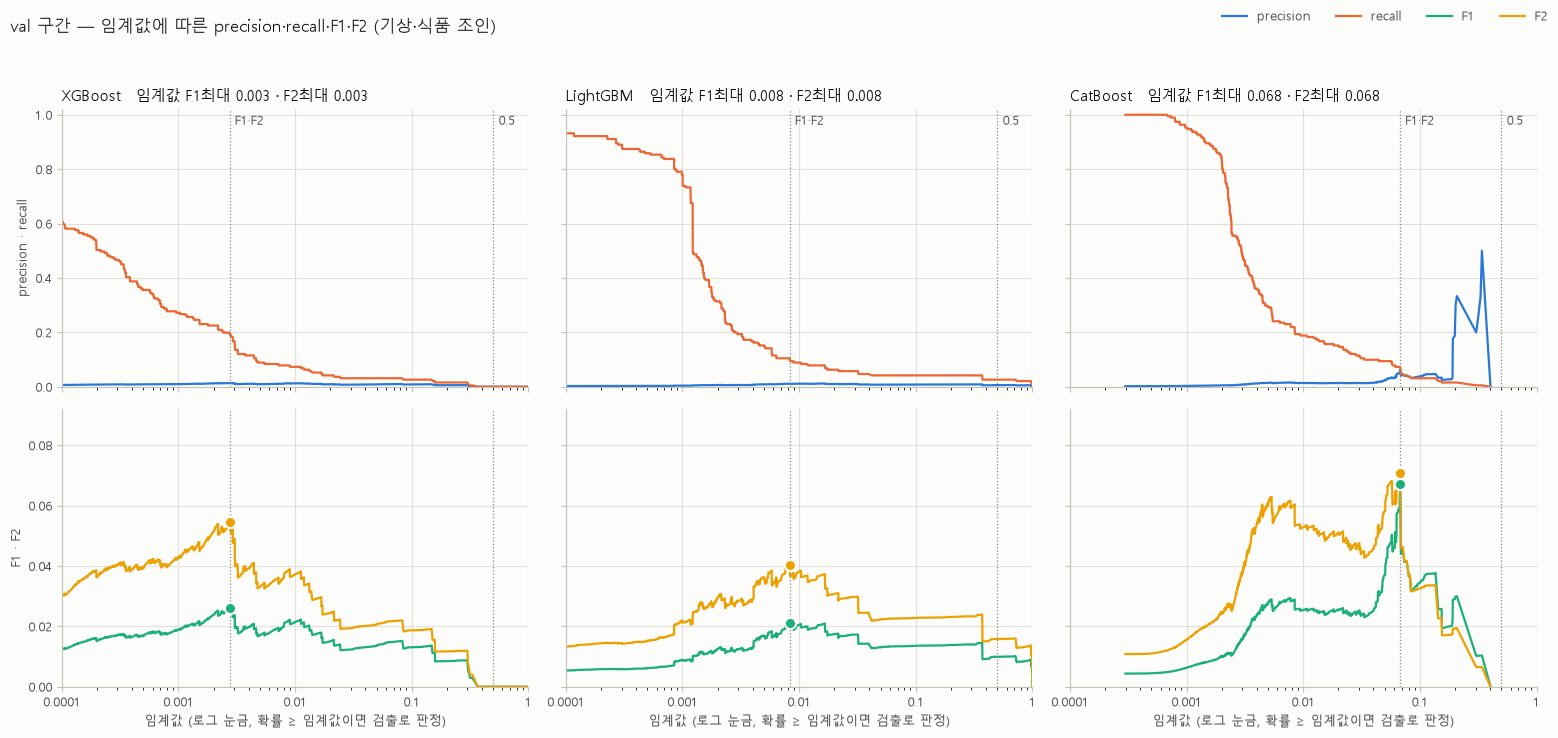

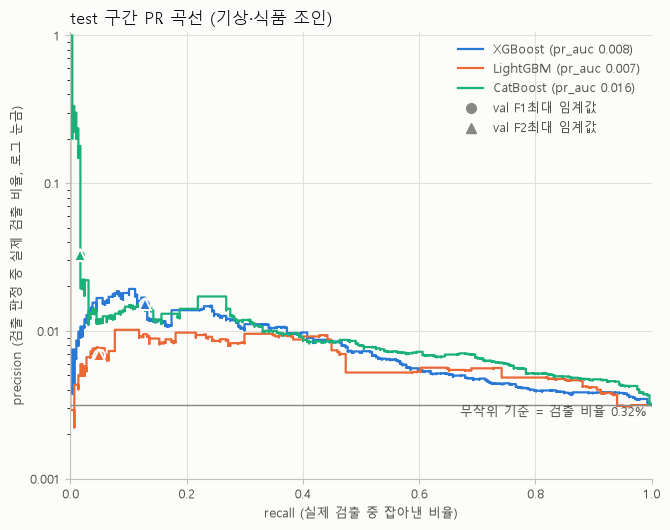

In [22]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
MODEL_COLOR = {'XGBoost': '#2a78d6', 'LightGBM': '#eb6834', 'CatBoost': '#1baf7a'}
METRIC_COLOR = {'precision': '#2a78d6', 'recall': '#eb6834', 'F1': '#1baf7a', 'F2': '#eda100'}
PLAIN = FuncFormatter(lambda v, _: f'{v:g}')
FIGURES = {}

def style_axes(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=AXIS, labelcolor=INK2, labelsize=9)

# 11-1. val 임계값별 지표
fig, axes = plt.subplots(2, len(models), figsize=(5.2 * len(models), 7.4), sharex=True, sharey='row', facecolor=SURFACE)
f_max = 0
for j, name in enumerate(models):
    precision, recall, thr = precision_recall_curve(ys['val'], proba['val'][name])
    precision, recall = precision[:-1], recall[:-1]
    curves = {'precision': precision, 'recall': recall,
              'F1': fbeta_curve(precision, recall, 1), 'F2': fbeta_curve(precision, recall, 2)}
    f_max = max(f_max, curves['F1'].max(), curves['F2'].max())
    t1, t2 = thresholds[name]['F1최대'], thresholds[name]['F2최대']
    ax_top, ax_bot = axes[0, j], axes[1, j]
    for ax, keys in [(ax_top, ['precision', 'recall']), (ax_bot, ['F1', 'F2'])]:
        style_axes(ax)
        ax.set_xscale('log')
        for k in keys:
            ax.plot(thr, curves[k], color=METRIC_COLOR[k], linewidth=1.6)
        for t in {t1, t2, 0.5}:
            ax.axvline(t, color=MUTED, linewidth=0.9, linestyle=':')
    for t, k in [(t1, 'F1'), (t2, 'F2')]:
        ax_bot.plot(t, curves[k][np.searchsorted(thr, t)], 'o', markersize=8, color=METRIC_COLOR[k],
                    markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
    if t1 == t2:
        marks = [(t1, 'F1·F2', 'left')]
    else:
        (lo, lo_name), (hi, hi_name) = sorted([(t1, 'F1'), (t2, 'F2')])
        marks = [(lo, lo_name, 'right'), (hi, hi_name, 'left')]
    for t, text, ha in marks + [(0.5, '0.5', 'left')]:
        ax_top.text(t, 1.0, f' {text} ', ha=ha, va='top', color=INK2, fontsize=9)
    ax_top.set_title(f'{name}   임계값 F1최대 {t1:.3f} · F2최대 {t2:.3f}', loc='left', color=INK, fontsize=10.5)
    ax_bot.set_xlabel('임계값 (로그 눈금, 확률 ≥ 임계값이면 검출로 판정)', color=INK2, fontsize=9)
for ax in axes.flat:
    ax.set_xlim(1e-4, 1)
    ax.xaxis.set_major_formatter(PLAIN)
axes[0, 0].set_ylim(0, 1.02)
axes[1, 0].set_ylim(0, f_max * 1.3)
axes[0, 0].set_ylabel('precision · recall', color=INK2, fontsize=9)
axes[1, 0].set_ylabel('F1 · F2', color=INK2, fontsize=9)
fig.legend(handles=[Line2D([], [], color=c, linewidth=1.6, label=k) for k, c in METRIC_COLOR.items()],
           loc='upper right', ncol=4, frameon=False, fontsize=9, labelcolor=INK2)
fig.suptitle('val 구간 — 임계값에 따른 precision·recall·F1·F2 (기상·식품 조인)', x=0.01, ha='left', color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
FIGURES['val_threshold_curves.png'] = fig
plt.show()

# 11-2. test PR 곡선
fig, ax = plt.subplots(figsize=(6.8, 5.4), facecolor=SURFACE)
style_axes(ax)
ax.set_yscale('log', nonpositive='mask')
pos_rate = ys['test'].mean()
for name in models:
    precision, recall, _ = precision_recall_curve(ys['test'], proba['test'][name])
    ap = average_precision_score(ys['test'], proba['test'][name])
    ax.plot(recall, precision, drawstyle='steps-post', color=MODEL_COLOR[name], linewidth=1.6, label=f'{name} (pr_auc {ap:.3f})')
    for rule, marker in [('F1최대', 'o'), ('F2최대', '^')]:
        row = metrics[(metrics['모델'] == name) & (metrics['구간'] == 'test') & (metrics['임계값 규칙'] == rule)].iloc[0]
        if row['TP'] > 0:
            ax.plot(row['recall'], row['precision'], marker=marker, markersize=8, linestyle='none',
                    color=MODEL_COLOR[name], markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=5)
ax.axhline(pos_rate, color=MUTED, linewidth=1)
ax.text(0.99, pos_rate, f'무작위 기준 = 검출 비율 {pos_rate:.2%}', transform=ax.get_yaxis_transform(),
        ha='right', va='top', color=INK2, fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(1e-3, 1.05)
ax.yaxis.set_major_formatter(PLAIN)
ax.set_xlabel('recall (실제 검출 중 잡아낸 비율)', color=INK2, fontsize=9)
ax.set_ylabel('precision (검출 판정 중 실제 검출 비율, 로그 눈금)', color=INK2, fontsize=9)
ax.set_title('test 구간 PR 곡선 (기상·식품 조인)', loc='left', color=INK, fontsize=12)
ax.legend(handles=ax.get_legend_handles_labels()[0] + [
    Line2D([], [], marker='o', linestyle='none', color=MUTED, markersize=7, label='val F1최대 임계값'),
    Line2D([], [], marker='^', linestyle='none', color=MUTED, markersize=7, label='val F2최대 임계값')],
    frameon=False, fontsize=9, labelcolor=INK2, loc='upper right')
fig.tight_layout()
FIGURES['test_pr_curve.png'] = fig
plt.show()

## 12. 어떤 칼럼을 썼나 — 칼럼 묶음별 중요도

모델이 나무를 나눌 때 어느 칼럼을 얼마나 썼는지를 묶음별 비율(%)로 본다. 이 값은 "그 칼럼으로 얼마나 잘 갈랐나"이지 "검출 원인"이 아니다.
- XGBoost: `total_gain`(칼럼별 이득 합계) · LightGBM: `gain` · CatBoost: `PredictionValuesChange`(기본 중요도)
- 묶음: LIMS 5칼럼(2_바로학습 피처), 식품 값 3칼럼, 식품 값 표기 3칼럼, 기상·대기 변수별 100칼럼

In [23]:
imp = {}
score = models['XGBoost'].get_booster().get_score(importance_type='total_gain')   # 'f0' … 칼럼 번호
imp['XGBoost'] = np.array([score.get(f'f{i}', 0.0) for i in range(len(FEATURES))])
imp['LightGBM'] = models['LightGBM'].booster_.feature_importance(importance_type='gain').astype(float)
imp['CatBoost'] = models['CatBoost'].get_feature_importance().astype(float)
IMPORTANCE = pd.DataFrame(imp, index=FEATURES)
IMPORTANCE = IMPORTANCE / IMPORTANCE.sum() * 100

def group_of(c):
    if c in FOOD_LABEL_COLS:
        return '식품 값 표기: ' + c
    if c in BASE_FEATURES:
        return '기본: ' + c
    if c in FOOD_COLS:
        return '식품: ' + FOOD_KO[c]
    v = c.rsplit('_d', 1)[0]
    return '기상·대기: ' + dict((x[0], x[1]) for x in VARIABLES)[v]

GROUP_IMP = IMPORTANCE.groupby(IMPORTANCE.index.map(group_of)).sum()
GROUP_IMP.loc[f'(합) LIMS {len(LIMS_FEATURES)}칼럼'] = IMPORTANCE.loc[LIMS_FEATURES].sum()
GROUP_IMP.loc['(합) 식품 값 표기 3칼럼'] = IMPORTANCE.loc[FOOD_LABEL_COLS].sum()
GROUP_IMP.loc['(합) 식품 3칼럼'] = IMPORTANCE.loc[FOOD_COLS].sum()
GROUP_IMP.loc['(합) 기상·대기 1,700칼럼'] = IMPORTANCE.loc[WX_COLS].sum()
display(GROUP_IMP.sort_values('XGBoost', ascending=False).round(2))
print('모델별 중요도 상위 10칼럼')
display(pd.DataFrame({m: IMPORTANCE[m].sort_values(ascending=False).head(10).round(2).reset_index()
                      .apply(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1).to_numpy() for m in models}))

,XGBoost,LightGBM,CatBoost
"(합) 기상·대기 1,700칼럼",57.37,95.05,62.59
(합) LIMS 9칼럼,42.61,2.20,30.08
기본: legal_dong_code,31.13,0.01,4.68
기상·대기: 강수량,13.38,4.47,4.93
기본: prdlst_code,10.42,0.00,3.66
기상·대기: 최대풍속,9.58,6.29,5.15
기상·대기: 토양수분,8.84,9.49,4.53
기상·대기: 일사량,6.44,8.69,6.30
기상·대기: 일산화탄소,3.60,17.14,6.36
기상·대기: 평균풍속,2.54,8.55,4.57


모델별 중요도 상위 10칼럼


,XGBoost,LightGBM,CatBoost
0,legal_dong_code (31.13),no2_d009 (5.98),addr_source (15.0)
1,prdlst_code (10.42),co_d069 (5.13),legal_dong_code (4.68)
2,rain_d088 (10.28),co_d016 (4.41),prdlst_code (3.66)
3,soil_moist_d048 (8.41),avg_wind_d021 (4.08),train_prdlst_code (3.42)
4,solar_rad_d020 (3.51),no2_d005 (2.84),ph (2.87)
5,max_wind_d054 (2.19),soil_moist_d064 (2.07),train_prdlst_nm (2.01)
6,max_wind_d048 (2.15),soil_t5_d083 (1.83),na_label (1.71)
7,max_wind_d038 (2.02),max_wind_d031 (1.68),ph_label (1.3)
8,co_d025 (1.9),avg_temp_d001 (1.66),na (0.89)
9,rain_d005 (1.81),soil_moist_d014 (1.61),lat (0.6)


## 13. MLflow 에 기록

2_바로학습과 같은 구조: 실험 `리스테리아_EXP1`, 부모 run `3_기상조인_후_학습` 1개 + 자식 run 9개(모델 3 × 임계값 규칙 3, 이름 `3_기상조인_후_학습 / 모델 / 규칙`).

| 기록 단위 | params (조건) | metrics·artifacts (결과) |
|---|---|---|
| 부모 run | 입력 파일·수정 시각, 조인 결과 폴더, 분할 기간·건수, 피처 묶음·개수, 조인 규칙, seed, 장치, 튜닝·불균형·조기 종료 여부, 임계값 규칙 | 그림 2개(`figures/`), `metrics.csv`, `predictions.parquet`(val·test 시료별 확률), `config.json`, `features.json`(피처 1,715개 이름), `join_summary.csv`·`food_summary.csv`·`food_parse.csv`(조인 점검), `importance.csv`·`importance_groups.csv` |
| 자식 run | 모델, 임계값 규칙·값, 장치, 하이퍼파라미터 전체(`hp.`) | val·test 지표(`val_`·`test_` + accuracy·precision·recall·f1·f2·roc_auc·pr_auc·TP·FN·FP·TN·n_total·n_pos·n_pred_pos), `threshold`, `fit_seconds` |

XGBoost 의 `feature_types`(1,715개 목록)처럼 너무 긴 하이퍼파라미터 값은 params 에는 요약만 넣고 전체는 `config.json` 에 둔다.

In [24]:
def model_params(name, model):
    return model.get_all_params() if name == 'CatBoost' else model.get_params()

def short(v, limit=500):
    s = v if isinstance(v, str) else json.dumps(v, ensure_ascii=False, default=str)
    if len(s) <= limit:
        return v
    if isinstance(v, (list, tuple)):
        return f'(길이 {len(v)} 목록 — config.json 참고)'
    return s[:limit - 20] + ' …(config.json 참고)'

def file_mtime(path):
    return datetime.fromtimestamp(Path(path).stat().st_mtime).isoformat(timespec='seconds')

INPUT = f'LIMS {len(LIMS_FEATURES)}칼럼 + 식품 3(값 표기 3) + 기상·대기 1,700칼럼'   # 입력 데이터 한 줄 설명
parent_params = {
    'input': INPUT,
    'data.X': str(X_path), 'data.X_mtime': file_mtime(X_path), 'data.X_shape': str(X.shape),
    'data.y': str(y_path), 'data.y_mtime': file_mtime(y_path),
    'data.join_dir': str(JOIN_DIR), 'data.join_mtime': file_mtime(JOIN_DIR / 'wx_avg_temp.parquet'),
    'data.raw_dir': str(RAW_DIR),
    **{f'split.{r["구간"]}': f'{r["시작일"]}~{r["종료일"]} | {r["행 수"]:,}행 | 검출 {r["검출(1)"]:,}건'
       for r in split_summary.to_dict('records')},
    'n_features': len(FEATURES),
    'features.base': json.dumps(LIMS_FEATURES, ensure_ascii=False),
    'features.food_label': json.dumps(FOOD_LABEL_COLS),
    'features.food': json.dumps(FOOD_COLS),
    'features.wx_vars': json.dumps(WX_VARS),
    'features.wx_lags': f'D-1~D-{LAG_DAYS} (<변수>_d001 = 기준일 전날)',
    'join.domestic': f'시료 lat·lon 유클리드 거리(도) 가까운 관측소 {K_NEAREST}곳 평균, 그날 값 있는 관측소 중, ASOS 는 그날 위치, 기본 칼럼 없으면 대체 칼럼',
    'join.overseas': 'global_factory_weather 같은 좌표(float32 로 맞춤)의 그날 값, 단위 다른 변수 제외',
    'join.food': 't_aw_cl: prdlst_code → train_prdlst_code, 범위=가운데 값, 부등호=경계값, 그 밖 결측. 값 표기(단일값·중앙·이상·이하·초과·미만)는 <값>_label 범주형 피처',
    'seed': SEED,
    **{f'device.{k}': v for k, v in DEVICE.items()},
    'tuning': '없음 (라이브러리 기본값)', 'imbalance': '없음', 'early_stopping': '없음',
    'threshold_rules': '0.5 / val F1최대 / val F2최대 (판정: 확률 >= 임계값)',
}
config = {
    'params': parent_params,
    'split': split_summary.astype({'시작일': str, '종료일': str}).to_dict('records'),
    'variables': [{'칼럼': v, '변수': ko, '단위': u, '국내 기본': p, '국내 대체': f, '해외': o} for v, ko, u, p, f, o in VARIABLES],
    'thresholds': thresholds, 'fit_seconds': fit_seconds,
    'key_params': {name: key_params(name, m) for name, m in models.items()},
    'hyperparameters': {name: model_params(name, m) for name, m in models.items()},
    'libraries': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
                  'scikit-learn': sklearn.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                  'catboost': cb.__version__, 'mlflow': mlflow.__version__},
}
pred_out = pd.concat([pd.DataFrame({
    KEY_COL: X[KEY_COL].to_numpy()[ROWS[s]], '구간': s, DATE_COL: X[DATE_COL].to_numpy()[ROWS[s]],
    'y': ys[s].to_numpy(), **{f'p_{name}': proba[s][name].to_numpy() for name in models}})
    for s in ['val', 'test']], ignore_index=True)
METRIC_KEYS = {c: c for c in SCORE_COLS + ['TP', 'FN', 'FP', 'TN']}
METRIC_KEYS.update({'전체 건수': 'n_total', '실제 검출': 'n_pos', '예측 양성 수': 'n_pred_pos'})

NOTEBOOK = r'리스테리아ML\EXP\1\3_기상조인_후_학습.ipynb'
STAGE = '3단계 — 기상·대기 17변수 × D-1~D-100 + 식품 3칼럼(값 표기 3칼럼) 조인 후 학습 (튜닝·불균형 처리 없음)'
with mlflow.start_run(run_name=RUN_NAME) as parent:
    mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE, 'mlflow.note.content': STAGE})
    mlflow.log_params(parent_params)
    for fname, fig in FIGURES.items():
        mlflow.log_figure(fig, f'figures/{fname}')
    mlflow.log_text('﻿' + metrics.to_csv(index=False), 'metrics.csv')
    mlflow.log_dict(config, 'config.json')
    mlflow.log_dict({'features': FEATURES, 'categorical': CAT_COLS}, 'features.json')
    mlflow.log_text('﻿' + JOIN_SUMMARY.to_csv(index=False), 'join_summary.csv')
    mlflow.log_text('﻿' + FOOD_SUMMARY.to_csv(index=False), 'food_summary.csv')
    mlflow.log_text('﻿' + FOOD_PARSE.to_csv(index=False), 'food_parse.csv')
    mlflow.log_text('﻿' + FOOD_LABEL_SUMMARY.to_csv(index=False), 'food_label_summary.csv')
    mlflow.log_text('﻿' + IMPORTANCE.reset_index(names='feature').to_csv(index=False), 'importance.csv')
    mlflow.log_text('﻿' + GROUP_IMP.reset_index(names='group').to_csv(index=False), 'importance_groups.csv')
    with tempfile.TemporaryDirectory() as tmp:
        pred_path = Path(tmp) / 'predictions.parquet'
        pred_out.to_parquet(pred_path, index=False)
        mlflow.log_artifact(str(pred_path))
    for name, model in models.items():
        hp = {f'hp.{k}': short(v) for k, v in model_params(name, model).items()}
        for rule, t in thresholds[name].items():
            with mlflow.start_run(run_name=f'{RUN_NAME} / {name} / {rule}', nested=True):
                mlflow.set_tags({'notebook': NOTEBOOK, 'stage': STAGE, 'model': name, 'threshold_rule': rule})
                mlflow.log_params({'input': INPUT, 'model': name, 'threshold_rule': rule, 'threshold': t, 'device': DEVICE[name], **hp})
                values = {'threshold': t, 'fit_seconds': fit_seconds[name]}
                for s in ['val', 'test']:
                    row = metrics[(metrics['모델'] == name) & (metrics['구간'] == s) & (metrics['임계값 규칙'] == rule)].iloc[0]
                    values.update({f'{s}_{key}': float(row[col]) for col, key in METRIC_KEYS.items()})
                mlflow.log_metrics(values)
PARENT_RUN_ID = parent.info.run_id
print('기록 완료 — 부모 run', RUN_NAME, PARENT_RUN_ID)

기록 완료 — 부모 run 3_기상조인_후_학습 7b308359eccf48058e7ee251ab0686ea


## 14. 2_바로학습과 비교 (test)

MLflow 에서 가장 최근의 `2_바로학습` 부모 run 과 그 자식 run 9개를 읽어, 같은 모델·같은 임계값 규칙끼리 test 지표를 나란히 놓는다. 행·분할·모델 인자는 같고, 다른 점은 **붙인 칼럼 1,706개**(기상·대기 1,700 + 식품 3 + 식품 값 표기 3)와 **CatBoost 장치**(2_바로학습 run 의 `device.CatBoost` 를 함께 출력)다.

In [25]:
def children_of(run_id):
    return mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT], filter_string=f"tags.mlflow.parentRunId = '{run_id}'")

base_parents = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT], filter_string="attributes.run_name = '2_바로학습'",
                                  order_by=['attributes.start_time DESC'])
base_parents = base_parents[base_parents.get('tags.mlflow.parentRunId', pd.Series(index=base_parents.index, dtype=object)).isna()]
assert len(base_parents), 'MLflow 에 2_바로학습 run 이 없음 — 2_바로학습.ipynb 를 먼저 실행해야 함'
base = base_parents.iloc[0]
print(f"비교 대상: 2_바로학습 run {base['run_id']} (시작 {base['start_time']:%Y-%m-%d %H:%M}) · CatBoost 장치 {base.get('params.device.CatBoost')}")

COMPARE = ['test_roc_auc', 'test_pr_auc', 'test_recall', 'test_precision', 'test_f2', 'test_TP', 'test_n_pred_pos']
def child_table(run_id, label):
    c = children_of(run_id)
    c = c.assign(모델=c['params.model'], 규칙=c['params.threshold_rule']).set_index(['모델', '규칙'])
    return c[[f'metrics.{m}' for m in COMPARE]].rename(columns=lambda s: s.removeprefix('metrics.test_')).add_prefix(f'{label} ')

cmp = child_table(base['run_id'], '바로').join(child_table(PARENT_RUN_ID, '기상'))
for m in ['roc_auc', 'pr_auc', 'recall']:
    cmp[f'차이 {m}'] = cmp[f'기상 {m}'] - cmp[f'바로 {m}']
order = pd.MultiIndex.from_product([['XGBoost', 'LightGBM', 'CatBoost'], ['0.5', 'F1최대', 'F2최대']], names=['모델', '규칙'])
COMPARISON = cmp.reindex(order)
cols = [f'{p} {m}' for m in ['roc_auc', 'pr_auc', 'recall', 'precision', 'TP', 'n_pred_pos'] for p in ['바로', '기상']] + ['차이 roc_auc', '차이 pr_auc', '차이 recall']
display(COMPARISON[cols].round(4))
with mlflow.start_run(run_id=PARENT_RUN_ID):
    mlflow.log_text('﻿' + COMPARISON.reset_index().to_csv(index=False), 'comparison_vs_2_바로학습.csv')
    mlflow.set_tag('compared_with', f"2_바로학습 {base['run_id']}")

비교 대상: 2_바로학습 run 2eba7aa25c4244bbaf36a7c136101a41 (시작 2026-10-01 08:10) · CatBoost 장치 CPU


바로 roc_auc  기상 roc_auc  바로 pr_auc  기상 pr_auc  바로 recall  \
모델       규칙                                                              
XGBoost  0.5       0.7236      0.6869     0.0102     0.0084     0.0000   
         F1최대      0.7236      0.6869     0.0102     0.0084     0.0348   
         F2최대      0.7236      0.6869     0.0102     0.0084     0.0523   
LightGBM 0.5       0.7651      0.6935     0.0145     0.0066     0.0070   
         F1최대      0.7651      0.6935     0.0145     0.0066     0.0418   
         F2최대      0.7651      0.6935     0.0145     0.0066     0.0418   
CatBoost 0.5       0.7551      0.7430     0.0132     0.0160     0.0000   
         F1최대      0.7551      0.7430     0.0132     0.0160     0.0418   
         F2최대      0.7551      0.7430     0.0132     0.0160     0.2230   

               기상 recall  바로 precision  기상 precision  바로 TP  기상 TP  \
모델       규칙                                                          
XGBoost  0.5      0.0070        0.0000        0.0048    0.0    2.0   
         F1최대     0.1289        0.0763        0.0153   10.0   37.0   
         F2최대     0.1289        0.0264        0.0153   15.0   37.0   
LightGBM 0.5      0.0209        0.1538        0.0051    2.0    6.0   
         F1최대     0.0488        0.0968        0.0069   12.0   14.0   
         F2최대     0.0488        0.0284        0.0069   12.0   14.0   
CatBoost 0.5      0.0000        0.0000        0.0000    0.0    0.0   
         F1최대     0.0174        0.0232        0.0327   12.0    5.0   
         F2최대     0.0174        0.0260        0.0327   64.0    5.0   

               바로 n_pred_pos  기상 n_pred_pos  차이 roc_auc  차이 pr_auc  차이 recall  
모델       규칙                                                                    
XGBoost  0.5            18.0          414.0     -0.0367    -0.0018     0.0070  
         F1최대          131.0         2416.0     -0.0367    -0.0018     0.0941  
         F2최대          569.0         2416.0     -0.0367    -0.0018     0.0767  
LightGBM 0.5            13.0         1175.0     -0.0716    -0.0079     0.0139  
         F1최대          124.0         2039.0     -0.0716    -0.0079     0.0070  
         F2최대          423.0         2039.0     -0.0716    -0.0079     0.0070  
CatBoost 0.5             0.0            0.0     -0.0122     0.0028     0.0000  
         F1최대          518.0          153.0     -0.0122     0.0028    -0.0244  
         F2최대         2466.0          153.0     -0.0122     0.0028    -0.2056

## 15. 결론 (2026-10-01 재실행, MLflow run `3_기상조인_후_학습`)

2026-10-01 에 입력이 바뀌어 다시 돌렸다: 검사기관 코드 `inspct_instt_code` 제거, 로마자로 적힌 한국 주소 78행을 국내로 옮김, 식품 값 표기 3칼럼 추가. 2026-09-29 실행의 결론과 수치는 작업기록 2026-09-29 항목에 있다(그때의 MLflow 기록은 `리스테리아ML/mlflow_backup_20261001/`).

1. **조인은 규칙대로 됐다.**
   - 국내 628,973행은 17개 변수 모두 99.93~100% 값이 있다. 빈 0.07%는 NAS 자료에 2020-02-29·2024-02-29 행이 없어서 생긴 것이다.
   - 해외 47,564행은 기온 3개·강수·일사량만 100% 값이 있고, 나머지 12개 변수는 100일 전부 결측이다.
   - 국내로 옮긴 78행은 국내 관측소 값이 붙었다. 다른 행의 값은 2026-09-29 조인 결과와 같다(5개 변수 대조).
   - 원자료로 한 칸씩 다시 계산한 2,550칸이 모두 저장값과 같았다(6절).
2. **식품 값은 절반 이하만 붙고, 검출 행에서 더 적게 붙는다.**
   - 값 있는 비율: 수분활성도 51.0%, 식품pH 39.5%, 염도 40.9%. 검출 행만 보면 27.3%, 14.2%, 14.7%.
   - 값 표기(5절 표): 수분활성도는 단일값 199,182 · 중앙 87,661 · 미만 44,887 · 이상 8,255 · 초과 5,329행. 식품pH 는 중앙 225,616 · 단일값 41,698 · 이상 2행. 염도는 중앙 168,443 · 단일값 108,398행. '이하'는 원문에 없다.
3. **test 성능 (2_바로학습 → 이 노트북, 임계값과 관계없는 지표)**

   | 모델 | roc_auc 바로 → 기상 | pr_auc 바로 → 기상 |
   |---|---|---|
   | XGBoost | 0.724 → 0.687 | 0.0102 → 0.0084 |
   | LightGBM | 0.765 → 0.694 | 0.0145 → 0.0066 |
   | CatBoost | 0.755(CPU) → 0.743(GPU) | 0.0132 → 0.0160 |

   - XGBoost·LightGBM 은 두 지표 모두 떨어졌다. CatBoost 는 roc_auc 가 떨어지고 pr_auc 는 올랐는데, 장치가 달라(바로학습 CPU, 이 노트북 GPU) 기상의 효과만으로 볼 수 없다.
   - 무작위 기준 pr_auc = test 검출 비율 0.00315.
4. **검사기관 코드를 뺀 영향** (2026-09-29 실행 → 이번 실행, test roc_auc / pr_auc)
   - 2_바로학습: XGBoost 0.786 / 0.0130 → 0.724 / 0.0102, LightGBM 0.784 / 0.0166 → 0.765 / 0.0145, CatBoost 0.798 / 0.0190 → 0.755 / 0.0132.
   - 이 노트북: XGBoost 0.757 / 0.0095 → 0.687 / 0.0084, LightGBM 0.758 / 0.0122 → 0.694 / 0.0066, CatBoost 0.783 / 0.0165 → 0.743 / 0.0160.
   - 이번 실행은 검사기관 제거 말고도 78행 이동·값 표기 추가가 함께 바뀌었다. 78행은 전부 불검출이고 전체의 0.01% 다.
5. **중요도(12절)**
   - XGBoost: `legal_dong_code` 31.1%, `prdlst_code` 10.4%, `rain_d088`(88일 전 강수량) 10.3%, `soil_moist_d048` 8.4%. 기상·대기 1,700칼럼 합 57.4%.
   - LightGBM: 기상·대기 칼럼 합 95.1%, LIMS 9칼럼 합 2.2%.
   - CatBoost: `addr_source` 15.0%, LIMS 9칼럼 합 30.1%, 기상·대기 합 62.6%, 식품 값 표기 3칼럼 합 3.5%.
   - LightGBM 은 test 시료의 1% 이상에, XGBoost 는 0.1% 이상에 확률 1.0 에 가까운 값을 줬다(10절 분포 표의 99%·99.9% 값).
6. **임계값**: 0.5 에서는 CatBoost 가 검출 판정 0건이다. val F2최대 임계값에서 test recall 은 XGBoost 12.9%(판정 2,416건 중 37건 적중), LightGBM 4.9%(2,039건 중 14건), CatBoost 1.7%(153건 중 5건)다.
7. **남은 의문**
   - 기상 칼럼이 실제 기상 효과가 아니라 장소·시기를 가려내는 표지로 쓰였을 가능성(추정 — 확인 필요).
   - 기상을 붙인 날짜·장소가 제조 시점·제조 장소로 확인되는 행은 제조일·제조사소재지 197,881행(검출 247)뿐이다(작업기록 2026-10-01). 이 범위만 따로 본 실험은 아직 없다.
   - CatBoost 를 같은 장치로 맞춘 비교.